# Operaciones de aprendizaje automático
## Maestría en Inteligencia Artificial Aplicada

### TC5061 | Proyecto MiBici: propuesta y base reproducible | Colaborativo

#### **Equipo:** 7
#### **Nombre:** Luis Arturo Sánchez Davila
#### **Matrícula:** A01840576

## Objetivo
Notebook de **exploración** del proyecto MiBici: carga y descripción del dataset de viajes que produce `dataset.py`, análisis exploratorio de datos (EDA) y evidencia para las decisiones de limpieza que acordará el equipo.

La pregunta que me corresponde es la **P3 (clustering)**: ¿qué grupos de estaciones comparten patrones de uso y dónde se ubican?

La lógica que se reutilice se trasladará al módulo del proyecto; en este notebook se desarrolla y se documenta la evidencia que la justifica.

## Dataset
**Datos abiertos de MiBici** (sistema de bicicleta pública del Área Metropolitana de Guadalajara), tal como los deja `tc5061_proyecto_equipo07/dataset.py`:
- **`data/interim/viajes_AAAA-MM_AAAA-MM.parquet`:** todos los meses del rango en un solo Parquet normalizado (nombres, fechas y tipos), sin limpiar. Es la entrada del EDA.
- **`data/processed/viajes_limpios_AAAA-MM_AAAA-MM.parquet`:** el mismo dataset después de las reglas de limpieza comunes (3.1).
- Cada registro es un viaje: `viaje_id`, `usuario_id`, `genero`, `anio_de_nacimiento`, `inicio_del_viaje`, `fin_del_viaje`, `origen_id` y `destino_id`; la ingesta agrega `periodo_archivo`.
- Fuente original: [Datos abiertos de MiBici](https://mibici.net/es/datos-abiertos/)
- Rango analizado: **enero de 2020 a septiembre de 2026**, acordado por el equipo para homologar el EDA. El portal retiró 2023-04 y 2023-05 el 14-oct-2026 y los volvió a publicar el 15-oct-2026 (ver `0.02-dsh-exploracion-carga`).

## Nota de reproducibilidad
El notebook se ejecuta desde la carpeta `notebooks/` con el entorno descrito en el README. Los CSV de `data/raw/` y los Parquet no se versionan en Git; lo versionado es el manifiesto `references/fuentes-datos.csv` (registros y SHA-256 por archivo). Los datos se generan con `make data` (`python -m tc5061_proyecto_equipo07.dataset todo`), que descarga lo que falte, verifica cada CSV contra el manifiesto y no se detiene en silencio si un mes no cuadra.

**Cifras:** las salidas y observaciones de las secciones 1 a 4 corresponden a la corrida del 15-oct-2026 con los **81 meses** del rango (27,086,557 viajes; 27,026,645 tras la limpieza). Una versión anterior de este notebook se escribió con 79 meses, porque el portal había retirado 2023-04 y 2023-05; sus cifras ya no aplican.

In [1]:
# Importación de librerías y registro de versiones (evidencia de reproducibilidad)
from pathlib import Path
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow
import seaborn as sns

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("pyarrow     :", pyarrow.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", sns.__version__)

Python      : 3.11.9
pandas      : 3.0.5
numpy       : 1.26.4
pyarrow     : 25.0.1
matplotlib  : 3.11.2
seaborn     : 0.13.2


## Configuración global

Las rutas, el rango de meses, la semilla y la paleta salen de `tc5061_proyecto_equipo07/config.py`, para que todos los notebooks y `dataset.py` usen los mismos valores:
- **Rutas:** `data/raw/`, `data/interim/` y `data/processed/`, más el manifiesto `references/fuentes-datos.csv`.
- **Rango:** meses inicial y final (inclusivos).
- **Random seed:** para que cualquier muestreo sea reproducible.
- **Colores:** paleta Okabe-Ito, apta para daltonismo, referida por nombre.
- **Opciones de visualización:** pandas muestra todas las columnas.

In [2]:
# Configuración compartida (el notebook se ejecuta desde notebooks/)
try:
    from tc5061_proyecto_equipo07 import dataset
except ModuleNotFoundError:  # paquete sin instalar; `make requirements` lo instala con `-e .`
    sys.path.insert(0, str(Path.cwd().parent))
    from tc5061_proyecto_equipo07 import dataset

from tc5061_proyecto_equipo07.config import (
    AZUL,
    DURACION_MAXIMA_MIN,
    FIGURES_DIR,
    MES_FIN,
    MES_INICIO,
    NARANJA,
    PROCESSED_DATA_DIR,
    PROJ_ROOT,
    RUTA_ESTACIONES_CRUDAS,
    RUTA_MANIFIESTO,
    RUTA_VIAJES_INTERIM,
    RUTA_VIAJES_LIMPIOS,
    SEMILLA,
    VERDE,
)

# Opciones de visualización de pandas
pd.set_option("display.max_columns", None)   # mostrar todas las columnas
pd.set_option("display.max_colwidth", None)  # no recortar textos largos

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

2026-10-15 21:25:08.486 | INFO     | tc5061_proyecto_equipo07.config:<module>:14 - PROJ_ROOT path is: /Users/lsanchez/Maestria_proyectos/MLOps-ProyectoMiBici-Equipo7


## Paso 1: Carga y descripción del dataset

En este paso se obtienen los Parquet mensuales, se leen y se valida que la carga sea completa antes de describir el dataset. Cualquier diferencia se documenta como hallazgo y se resuelve con evidencia, no con supuestos.


### 1.1 Obtención de los datos con `dataset.py`

La ingesta ya no vive en el notebook. `tc5061_proyecto_equipo07/dataset.py` la ejecuta en tres etapas (cada una es un comando; `todo` las corre en orden):

| Etapa | Entrada | Salida |
|---|---|---|
| `descargar` | Portal de MiBici | CSV en `data/raw/` y manifiesto `references/fuentes-datos.csv` (registros y SHA-256) |
| `construir` | CSV de `data/raw/` | `data/interim/viajes_AAAA-MM_AAAA-MM.parquet`, normalizado y validado |
| `limpiar` | Parquet de `data/interim/` | `data/processed/viajes_limpios_AAAA-MM_AAAA-MM.parquet` |

La codificación (UTF-8 o latin-1), el encabezado dañado de 2024-02 y 2024-05, y los dos formatos de fecha se resuelven en `dataset.py`; se detiene si un encabezado es desconocido, si un valor no se convierte, si un viaje inicia fuera del mes de su archivo o si un CSV no coincide con el manifiesto. Esta celda solo verifica que los datos existan y los compara contra el manifiesto.

In [3]:
# Los datos los produce dataset.py: descargar -> construir -> limpiar (make data)
EJECUTAR_INGESTA = False  # True: corre dataset.todo desde aquí (descarga lo que falte; puede tardar)

if EJECUTAR_INGESTA:
    dataset.todo(MES_INICIO, MES_FIN)

if not RUTA_VIAJES_INTERIM.exists():
    raise FileNotFoundError(
        f"Falta {RUTA_VIAJES_INTERIM.name}; ejecutar `make data` o poner EJECUTAR_INGESTA = True"
    )

# Lo que debe haber en el rango, según el manifiesto versionado en Git
manifiesto = pd.read_csv(RUTA_MANIFIESTO)
manifiesto = manifiesto[manifiesto["archivo"].str.startswith("datos_abiertos")
                        & manifiesto["periodo"].between(MES_INICIO, MES_FIN)]
print("Archivos de viajes en el manifiesto:", len(manifiesto))
print("Registros esperados                :", f"{int(manifiesto['registros'].sum()):,}")
print("Versión de los datos               :", dataset.version_datos())

Archivos de viajes en el manifiesto: 81
Registros esperados                : 27,086,557
Versión de los datos               : c3b84e1ab511


**Observaciones de la obtención:**
- **Origen:** los datos los genera `dataset.py`; el notebook ya no descarga ni convierte nada, de modo que todos los notebooks parten del mismo archivo.
- **Trazabilidad:** el manifiesto (`references/fuentes-datos.csv`) guarda el número de registros y el SHA-256 de cada CSV, y la versión de los datos es el hash de esos hashes. Si un mes cambia en el portal, cambia la versión y se ve en el diff de Git.
- **Meses sin datos:** `MESES_SIN_PUBLICAR` (en `config.py`) solo tolera 2023-04 y 2023-05 si el portal vuelve a retirarlos; cualquier otro hueco detiene la descarga.
- **Sustituye:** la conversión CSV a Parquet que antes estaba en esta sección (y que no estaba versionada en el paquete) y la comparación contra los Parquet de `0.01`.

In [4]:
# Lectura del Parquet normalizado (viajes sin limpiar) y validación contra el manifiesto
viajes = pd.read_parquet(RUTA_VIAJES_INTERIM)

esperados = int(manifiesto["registros"].sum())
assert len(viajes) == esperados, (
    f"El Parquet tiene {len(viajes):,} registros y el manifiesto indica {esperados:,}; "
    "ejecutar `dataset construir`"
)

# Los meses sin datos se calculan de los datos, no de una lista fija
periodos_en_datos = set(viajes["periodo_archivo"].astype(str).unique())
MESES_SIN_DATOS = [str(p) for p in pd.period_range(MES_INICIO, MES_FIN, freq="M")
                   if str(p) not in periodos_en_datos]

print("Archivos leídos:", len(periodos_en_datos))
print(f"Registros      : {len(viajes):,}")
print("Columnas       :", viajes.shape[1])
print("Meses sin datos:", MESES_SIN_DATOS or "ninguno")

Archivos leídos: 81
Registros      : 27,086,557
Columnas       : 9
Meses sin datos: ninguno


**Observaciones de la lectura:**
- **Fuente:** `data/interim/viajes_2020-01_2026-09.parquet`, generado por `dataset.construir`, que verificó el SHA-256 de cada CSV contra el manifiesto y que no se perdieran registros.
- **Validación:** el número de registros leídos coincide con el del manifiesto; la celda se detiene si no.
- **Meses:** los meses del rango sin archivo se calculan de los datos (`MESES_SIN_DATOS`). Con los 81 meses publicados no hay ninguno; si el portal vuelve a retirar 2023-04 y 2023-05, aparecen aquí y se excluyen de la tabla de demanda.
- **Cifras:** el total de viajes, el mes con menos viajes (2020-04) y el de más viajes (2026-09) se leen de las salidas de arriba y de 2.3.

### 1.3 Descripción del dataset

Se revisan los tipos, los nulos y el rango de fechas para saber qué columnas requieren limpieza.

In [5]:
# Columnas, tipos, valores no nulos y memoria
viajes.info(show_counts=True, memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 27086557 entries, 0 to 27086556
Data columns (total 9 columns):
 #   Column              Non-Null Count     Dtype         
---  ------              --------------     -----         
 0   viaje_id            27086557 non-null  Int64         
 1   usuario_id          27086557 non-null  Int64         
 2   genero              26948912 non-null  category      
 3   anio_de_nacimiento  27051936 non-null  Int16         
 4   inicio_del_viaje    27086557 non-null  datetime64[us]
 5   fin_del_viaje       27086557 non-null  datetime64[us]
 6   origen_id           27086557 non-null  Int32         
 7   destino_id          27086557 non-null  Int32         
 8   periodo_archivo     27086557 non-null  category      
dtypes: Int16(1), Int32(2), Int64(2), category(2), datetime64[us](2)
memory usage: 1.2 GB


In [6]:
# Nulos y valores distintos por columna
resumen = pd.DataFrame({
    "nulos": viajes.isna().sum(),
    "% nulos": (viajes.isna().mean() * 100).round(2),
    "distintos": viajes.nunique(),
})
resumen

,nulos,% nulos,distintos
viaje_id,0,0.00,27085799
usuario_id,0,0.00,81245
genero,137645,0.51,2
anio_de_nacimiento,34621,0.13,87
inicio_del_viaje,0,0.00,23238062
fin_del_viaje,0,0.00,23190194
origen_id,0,0.00,475
destino_id,0,0.00,475
periodo_archivo,0,0.00,81


In [7]:
# Rango de fechas de inicio y fin de los viajes
print("Inicio:", viajes["inicio_del_viaje"].min(), "->", viajes["inicio_del_viaje"].max())
print("Fin   :", viajes["fin_del_viaje"].min(), "->", viajes["fin_del_viaje"].max())

Inicio: 2020-01-01 06:02:20 -> 2026-09-30 23:59:48
Fin   : 2020-01-01 06:05:38 -> 2026-10-01 00:14:52


**Observaciones de la descripción del dataset:**
- **Estructura:** 27,086,557 registros y 9 columnas (las 8 originales más `periodo_archivo`). `genero` y `periodo_archivo` son categorías; los identificadores, el año de nacimiento y las estaciones son enteros que admiten nulos.
- **Nulos:** solo `genero` (137,645, 0.51 %) y `anio_de_nacimiento` (34,621, 0.13 %) tienen valores nulos; las otras siete columnas están completas, incluidas las fechas.
- **Identificadores repetidos:** 27,085,799 `viaje_id` distintos para 27,086,557 registros, es decir, 758 repetidos; en 2.2 se confirma que son filas idénticas.
- **Fechas:** los viajes inician entre 2020-01-01 06:02:20 y 2026-09-30 23:59:48; el fin llega hasta 2026-10-01 00:14:52, porque los viajes iniciados al final de septiembre terminan en octubre.
- **Limitación:** el rango de fechas confirma el periodo pero no la continuidad: los meses con datos se ven en la sección 2.3.

## Paso 2: Análisis exploratorio de datos (EDA)

En este paso se explora el dataset unido **sin modificarlo**: cada hallazgo se cuantifica y se documenta para que el equipo acuerde su tratamiento en la limpieza. Las preguntas que guían el EDA salen del ML Canvas (`references/ml-canvas.md`):
- **Calidad:** ¿qué registros no se pueden usar tal cual (duplicados, duraciones, estaciones sin nomenclatura)?
- **Tiempo:** ¿cómo evoluciona el volumen y qué patrones horarios y semanales hay? Es la base de P1.
- **Estaciones:** ¿qué tan concentrada está la demanda y qué estaciones acumulan o pierden bicicletas? Es la base de P2 y P3.

Solo se muestran **agregados**; no se imprimen filas con `usuario_id`.

### 2.1 Preparación

Se cargan la nomenclatura de estaciones y tres variables derivadas: duración en minutos, hora del día y día de la semana (0 = lunes).

In [8]:
# Variables derivadas para el EDA (las columnas originales no cambian)
viajes["duracion_min"] = (viajes["fin_del_viaje"] - viajes["inicio_del_viaje"]).dt.total_seconds() / 60
viajes["hora"] = viajes["inicio_del_viaje"].dt.hour.astype("int8")
viajes["dia_semana"] = viajes["inicio_del_viaje"].dt.dayofweek.astype("int8")

# Nomenclatura de estaciones (misma detección de codificación que los viajes)
ruta_nomenclatura = sorted(RUTA_ESTACIONES_CRUDAS.glob("nomenclatura_*.csv"))[-1]
nomenclatura = pd.read_csv(ruta_nomenclatura,
                           encoding=dataset.detectar_codificacion(ruta_nomenclatura.read_bytes()))

print("Nomenclatura:", ruta_nomenclatura.name, "|", len(nomenclatura), "estaciones")
print(f"Memoria del DataFrame: {viajes.memory_usage(deep=True).sum() / 1024**3:.1f} GB")
nomenclatura.describe().T

Nomenclatura: nomenclatura_2026_09.csv | 484 estaciones
Memoria del DataFrame: 1.5 GB


,count,mean,std,min,25%,50%,75%,max
id,484.0,254.758264,148.293765,2.000000,129.750000,252.000000,379.250000,519.000000
latitude,484.0,20.678520,0.022032,20.636130,20.665077,20.674390,20.688609,20.739523
longitude,484.0,-103.361871,0.031626,-103.433215,-103.384164,-103.362443,-103.339320,-103.297112
dpcapacity,484.0,16.882231,4.126942,0.000000,15.000000,15.000000,19.000000,39.000000


### 2.2 Calidad de los datos

Antes de buscar patrones se mide qué parte del dataset no es utilizable tal cual. Se revisan cuatro cosas:
- **Duplicados:** un mismo `viaje_id` repetido, y si la fila completa también lo está (duplicado exacto) o difiere (conflicto).
- **Duración:** negativa, cero y extrema. Un viaje de duración cero suele ser un desbloqueo fallido; uno de más de 24 horas, una bicicleta no devuelta.
- **Año de nacimiento:** solo se cuentan valores imposibles; la variable no se usará en el modelado.
- **Estaciones sin nomenclatura:** sin capacidad ni ubicación no se pueden usar en P2 ni P3.

In [9]:
# Duplicados: identificadores repetidos y filas completas repetidas
COLUMNAS_ORIGINALES = ["viaje_id", "usuario_id", "genero", "anio_de_nacimiento",
                       "inicio_del_viaje", "fin_del_viaje", "origen_id", "destino_id"]
ids_repetidos = int(viajes["viaje_id"].duplicated().sum())
filas_repetidas = int(viajes.duplicated(subset=COLUMNAS_ORIGINALES).sum())

print(f"Registros con viaje_id ya visto      : {ids_repetidos:,}")
print(f"Filas completas repetidas            : {filas_repetidas:,}")
print(f"Ids repetidos con datos distintos    : {ids_repetidos - filas_repetidas:,}")

Registros con viaje_id ya visto      : 758
Filas completas repetidas            : 758
Ids repetidos con datos distintos    : 0


In [10]:
# Duración del viaje en minutos: anomalías y percentiles
duracion = viajes["duracion_min"]
negativas = int((duracion < 0).sum())
ceros = int((duracion == 0).sum())
mas_de_24h = int((duracion > 24 * 60).sum())

print(f"Duración negativa : {negativas:,}")
print(f"Duración cero     : {ceros:,} ({ceros / len(viajes):.2%})")
print(f"Más de 24 horas   : {mas_de_24h:,}")
print(f"Máxima            : {duracion.max() / 60:.1f} horas")
duracion.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99, .999]).round(2).to_frame("duracion_min")

Duración negativa : 0
Duración cero     : 55,035 (0.20%)
Más de 24 horas   : 159
Máxima            : 469.2 horas


,duracion_min
count,27086557.00
mean,11.00
std,15.48
min,0.00
1%,0.20
5%,2.02
25%,5.70
50%,9.45
75%,14.75
95%,24.15


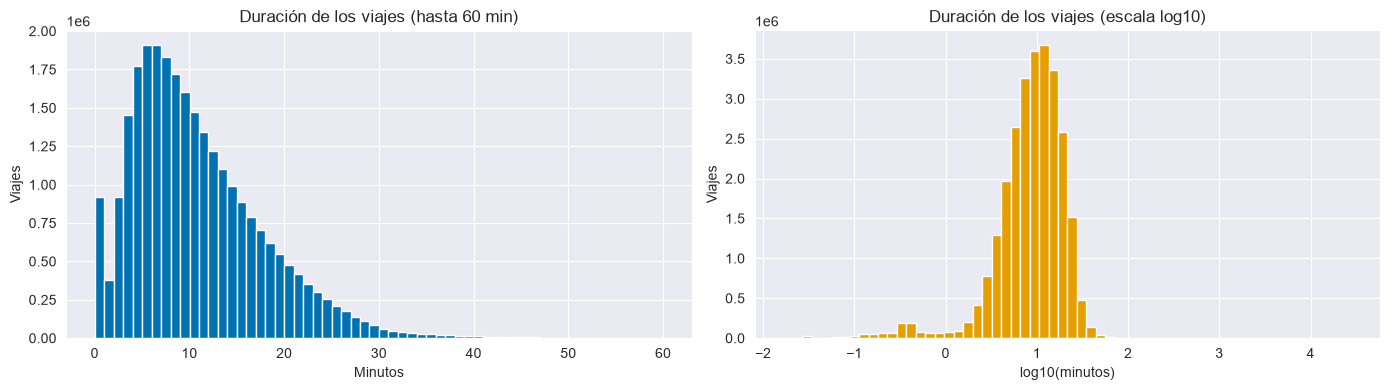

In [11]:
# Distribución de la duración: viajes de hasta 60 minutos y escala logarítmica de todos los positivos
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))

duracion[(duracion > 0) & (duracion <= 60)].plot.hist(bins=60, ax=ejes[0], color=AZUL)
ejes[0].set_title("Duración de los viajes (hasta 60 min)")
ejes[0].set_xlabel("Minutos")
ejes[0].set_ylabel("Viajes")

np.log10(duracion[duracion > 0]).plot.hist(bins=60, ax=ejes[1], color=NARANJA)
ejes[1].set_title("Duración de los viajes (escala log10)")
ejes[1].set_xlabel("log10(minutos)")
ejes[1].set_ylabel("Viajes")

plt.tight_layout()
plt.show()

In [12]:
# Año de nacimiento: solo se cuentan valores imposibles (agregados, sin filas individuales)
anio = viajes["anio_de_nacimiento"]
antes_1900 = int((anio < 1900).sum())
despues_2010 = int((anio > 2010).sum())
print(f"Anterior a 1900 : {antes_1900:,}")
print(f"Posterior a 2010: {despues_2010:,}")
print(f"Plausible (1920 a 2010): {anio.between(1920, 2010).sum() / anio.notna().sum():.2%} de los registros con dato")

Anterior a 1900 : 1,255
Posterior a 2010: 2,101
Plausible (1920 a 2010): 99.99% de los registros con dato


In [13]:
# Estaciones de los viajes que no están en la nomenclatura vigente
ids_nomenclatura = set(nomenclatura["id"])
ids_usados = set(viajes["origen_id"].dropna().unique()) | set(viajes["destino_id"].dropna().unique())
ids_sin_nomenclatura = sorted(ids_usados - ids_nomenclatura)

viajes_afectados = int((~viajes["origen_id"].isin(ids_nomenclatura) | ~viajes["destino_id"].isin(ids_nomenclatura)).sum())
sin_capacidad = int((nomenclatura["dpcapacity"] == 0).sum())

print("Estaciones con viajes         :", len(ids_usados))
print("Estaciones en la nomenclatura :", len(ids_nomenclatura))
print("Ids sin nomenclatura          :", ids_sin_nomenclatura)
print(f"Viajes afectados              : {viajes_afectados:,} ({viajes_afectados / len(viajes):.3%})")
print("Estaciones con capacidad 0    :", sin_capacidad)

Estaciones con viajes         : 475
Estaciones en la nomenclatura : 484
Ids sin nomenclatura          : [124, 405, 407]
Viajes afectados              : 3,961 (0.015%)
Estaciones con capacidad 0    : 4


In [14]:
# Resumen de calidad: registros afectados por hallazgo
total = len(viajes)
resumen_calidad = pd.DataFrame({
    "hallazgo": ["Filas completas repetidas", "Duración cero", "Duración mayor a 24 h",
                 "Año de nacimiento anterior a 1900", "Año de nacimiento posterior a 2010",
                 "Origen o destino sin nomenclatura", "Género nulo", "Año de nacimiento nulo"],
    "registros": [filas_repetidas, ceros, mas_de_24h, antes_1900, despues_2010, viajes_afectados,
                  int(viajes["genero"].isna().sum()), int(viajes["anio_de_nacimiento"].isna().sum())],
})
resumen_calidad["% del total"] = (resumen_calidad["registros"] / total * 100).round(3)
resumen_calidad

,hallazgo,registros,% del total
0,Filas completas repetidas,758,0.003
1,Duración cero,55035,0.203
2,Duración mayor a 24 h,159,0.001
3,Año de nacimiento anterior a 1900,1255,0.005
4,Año de nacimiento posterior a 2010,2101,0.008
5,Origen o destino sin nomenclatura,3961,0.015
6,Género nulo,137645,0.508
7,Año de nacimiento nulo,34621,0.128


**Observaciones de la calidad de los datos:**
- **Duplicados:** 758 registros repiten un `viaje_id` ya visto y los 758 son filas idénticas en todas las columnas; no hay identificadores repetidos con datos distintos. Eliminarlos no implica elegir entre versiones en conflicto.
- **Duración:** ninguna es negativa. 55,035 viajes (0.20 %) duran cero minutos y 159 duran más de 24 horas, con un máximo de 469.2 horas. La mediana es 9.45 min y el 99 % dura 32.80 min o menos; el 99.9 % no pasa de 58.72 min. El volumen extremo es mínimo, pero distorsiona la media (11.00 min) y la desviación (15.48 min) por una cola muy larga.
- **Año de nacimiento:** 1,255 valores anteriores a 1900 y 2,101 posteriores a 2010 (0.012 % del total entre ambos); el 99.99 % de los registros con dato cae entre 1920 y 2010. La variable no se usará en el modelado, por lo que el hallazgo solo importa si se describe a los usuarios.
- **Estaciones:** 475 estaciones tienen viajes y la nomenclatura vigente tiene 484. Tres identificadores (124, 405 y 407) aparecen en viajes y no en la nomenclatura: 3,961 viajes (0.015 %). Cuatro estaciones de la nomenclatura tienen capacidad 0.
- **Impacto:** ningún hallazgo supera el 0.51 % del total; el más grande son los nulos de `genero` (0.51 %). Los que obligarían a excluir registros (duplicados, duración cero o extrema y estaciones sin nomenclatura) suman como máximo 59,913 registros (0.22 %), sin descontar traslapes. La limpieza no compromete el tamaño del dataset.

### 2.3 Volumen de viajes en el tiempo

La serie mensual muestra la tendencia, el efecto de la pandemia y la continuidad de los 81 meses del rango (2023-04 y 2023-05 estuvieron retirados del portal y volvieron a publicarse). Es el primer insumo para decidir si P1 necesita un indicador de periodo y cómo calcular los rezagos.

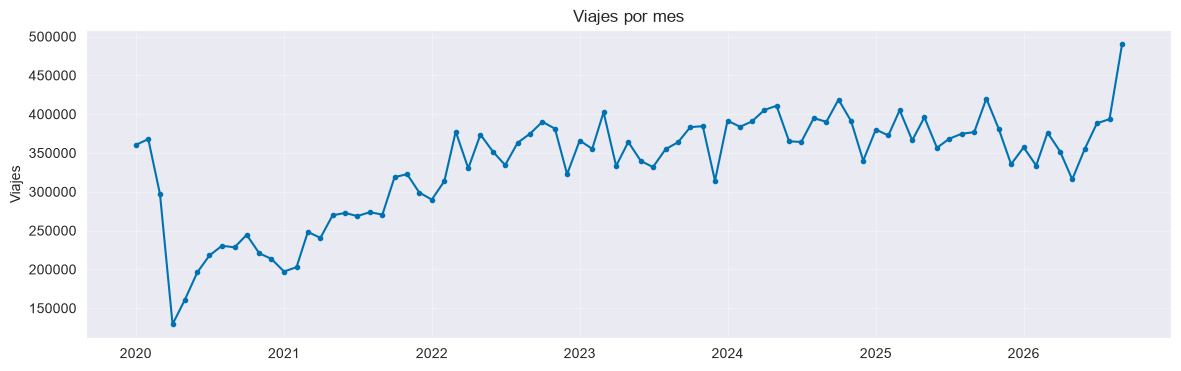

Mes con menos viajes: 2020-04 (129,276)
Mes con más viajes  : 2026-09 (490,056)
Mediana mensual     : 356,611
Meses sin dato      : []


In [15]:
# Viajes por mes sobre el calendario completo del rango (los meses sin archivo quedan como NaN)
mensual = viajes.groupby("periodo_archivo", observed=True).size()
mensual.index = pd.PeriodIndex(mensual.index.astype(str), freq="M")
mensual = mensual.reindex(pd.period_range(MES_INICIO, MES_FIN, freq="M"))

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(mensual.index.to_timestamp(), mensual.values, marker="o", markersize=3, color=AZUL)
ax.set_title("Viajes por mes")
ax.set_ylabel("Viajes")
ax.grid(alpha=0.3)
plt.show()

print("Mes con menos viajes:", mensual.idxmin(), f"({mensual.min():,.0f})")
print("Mes con más viajes  :", mensual.idxmax(), f"({mensual.max():,.0f})")
print(f"Mediana mensual     : {mensual.median():,.0f}")
print("Meses sin dato      :", [str(p) for p in mensual[mensual.isna()].index])

In [16]:
# Viajes por año: total, promedio por mes con dato y variación contra el año anterior
anual = mensual.groupby(mensual.index.year).agg(viajes="sum", meses_con_dato="count")
anual["promedio_mensual"] = (anual["viajes"] / anual["meses_con_dato"]).round(0)
anual["variacion_vs_anio_previo_%"] = (anual["promedio_mensual"].pct_change() * 100).round(1)
anual

,viajes,meses_con_dato,promedio_mensual,variacion_vs_anio_previo_%
2020,2866072,12,238839.0,NaN
2021,3184410,12,265368.0,11.1
2022,4202942,12,350245.0,32.0
2023,4293115,12,357760.0,2.1
2024,4645921,12,387160.0,8.2
2025,4532032,12,377669.0,-2.5
2026,3362065,9,373563.0,-1.1


**Observaciones del volumen en el tiempo:**
- **Tendencia:** el promedio mensual crece de 238,839 viajes en 2020 a 387,160 en 2024 y se estabiliza: 377,669 en 2025 (−2.5 %) y 373,563 en 2026 (−1.1 %, con 9 meses). Después de 2024 el sistema muestra una meseta, no un crecimiento.
- **Pandemia:** el volumen cae de 367,864 viajes en febrero de 2020 a 129,276 en abril (−64.9 %). El primer mes que supera el nivel de febrero de 2020 es marzo de 2022 (377,505), dos años después. Un modelo entrenado con 2020 aprende un régimen que no se repite; se justifica un indicador de periodo o excluir 2020 de los ajustes.
- **Continuidad:** los 81 meses del rango tienen datos. 2023-04 (333,211) y 2023-05 (364,184) estuvieron retirados del portal el 14-oct-2026 y volvieron a publicarse al día siguiente; con ellos la serie ya no tiene hueco y los rezagos y ventanas que cruzan esos meses se pueden calcular. Abril cae 17.2 % contra marzo (402,460) y mayo se recupera. Si el portal los retira de nuevo, `MESES_SIN_DATOS` los excluye de la tabla de demanda y no se imputan.
- **Estacionalidad:** hay caídas recurrentes en diciembre (por ejemplo, 299,005 en 2021-12 y 314,164 en 2023-12), consistentes con el periodo vacacional. El mes del año es una variable relevante para P1.
- **Último mes:** 2026-09 (490,056) es el máximo de toda la serie: 24.5 % más que agosto (393,524) y 30.1 % más que septiembre de 2025 (376,789). El EDA no explica la causa; hay que verificar que sea un valor real y no una carga atípica antes de que forme parte del conjunto de prueba.

### 2.4 Patrones por hora y día de la semana

Se mide qué proporción de los viajes ocurre en cada hora y día. Un perfil con dos picos (mañana y tarde) en días laborales indica uso para ir al trabajo; es la señal que justifica incluir `hora`, `dia_semana` y festivos como features de P1 y P2.

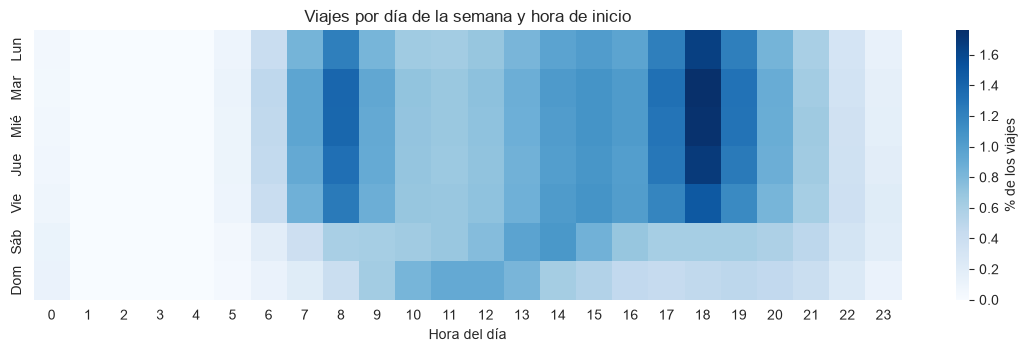

In [17]:
# Proporción de viajes por día de la semana y hora de inicio
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
conteo = viajes.groupby(["dia_semana", "hora"], observed=True).size().unstack(fill_value=0)
proporcion = conteo / conteo.to_numpy().sum() * 100

fig, ax = plt.subplots(figsize=(14, 3.5))
sns.heatmap(proporcion, cmap="Blues", ax=ax, yticklabels=DIAS, cbar_kws={"label": "% de los viajes"})
ax.set_title("Viajes por día de la semana y hora de inicio")
ax.set_xlabel("Hora del día")
ax.set_ylabel("")
plt.show()

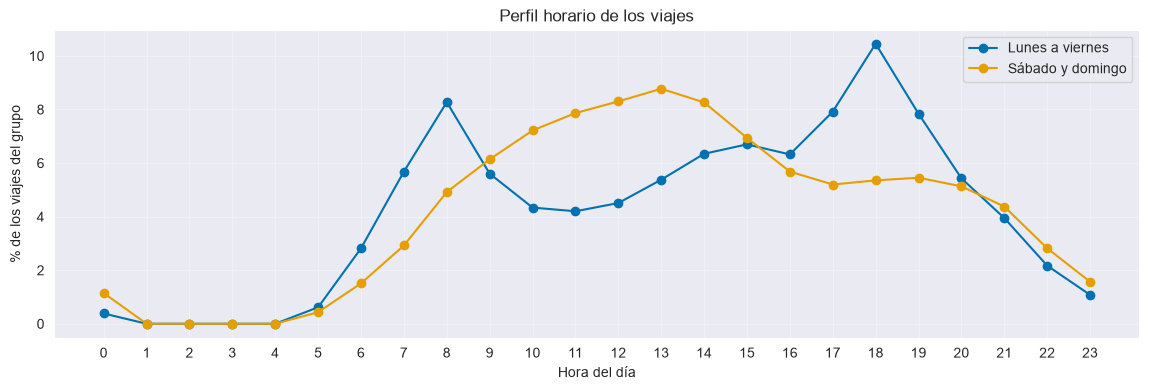

Horas pico lunes a viernes: [18, 8, 17]
Horas pico fin de semana  : [13, 12, 14]
Viajes en fin de semana   : 20.4%


In [18]:
# Perfil horario: días laborales frente a fin de semana (proporción dentro de cada grupo)
laboral = conteo.loc[0:4].sum()
fin_de_semana = conteo.loc[5:6].sum()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(laboral.index, laboral / laboral.sum() * 100, marker="o", color=AZUL, label="Lunes a viernes")
ax.plot(fin_de_semana.index, fin_de_semana / fin_de_semana.sum() * 100, marker="o", color=NARANJA, label="Sábado y domingo")
ax.set_title("Perfil horario de los viajes")
ax.set_xlabel("Hora del día")
ax.set_ylabel("% de los viajes del grupo")
ax.set_xticks(range(24))
ax.grid(alpha=0.3)
ax.legend()
plt.show()

print("Horas pico lunes a viernes:", laboral.nlargest(3).index.tolist())
print("Horas pico fin de semana  :", fin_de_semana.nlargest(3).index.tolist())
print(f"Viajes en fin de semana   : {fin_de_semana.sum() / (laboral.sum() + fin_de_semana.sum()):.1%}")

**Observaciones de los patrones horarios:**
- **Días laborales:** dos picos claros a las 8:00 (8.3 % de los viajes) y a las 18:00 (10.5 %), con un valle de 10:00 a 11:00 (4.2 a 4.3 %). Las horas 7, 8, 17 y 18 concentran el 32.3 % de los viajes laborales. Es el patrón de traslado al trabajo.
- **Fin de semana:** un solo pico amplio entre las 11:00 y las 14:00, con máximo a las 13:00 (8.8 %). Sábado y domingo concentran el 20.4 % de los viajes, por debajo del 28.6 % que corresponde a 2 de 7 días: el uso es predominantemente laboral.
- **Horario de servicio:** entre la 1:00 y las 4:59 hay solo 194 viajes en 27.1 millones (0.0007 %); la hora 0 tiene 145,857 (0.5 %), con más peso en sábado y domingo (31,410 y 31,698). El sistema prácticamente no opera de madrugada.
- **Implicación:** `hora`, `dia_semana` y `es_fin_de_semana` son features justificadas por evidencia. Para P1, las horas de 1:00 a 4:59 no deben rellenarse con ceros como si fueran demanda cero medida: son horas de servicio cerrado y conviene excluirlas o tratarlas aparte.

### 2.5 Demanda y balance por estación

Se mide cuántos viajes inician y terminan en cada estación. Dos preguntas:
- **Concentración:** si pocas estaciones concentran la demanda, el modelo de P1 se evaluará sobre todo en ellas.
- **Balance neto:** `llegadas − salidas`. Una estación con balance muy positivo acumula bicicletas (riesgo de quedarse sin anclajes) y una con balance muy negativo las pierde (riesgo de quedarse sin bicicletas). Es la base de P2.

In [19]:
# Salidas, llegadas y balance neto por estación, unidas a la nomenclatura
salidas = viajes["origen_id"].value_counts()
llegadas = viajes["destino_id"].value_counts()
estaciones = pd.DataFrame({"salidas": salidas, "llegadas": llegadas}).fillna(0).astype(int)
estaciones["neto"] = estaciones["llegadas"] - estaciones["salidas"]
estaciones["neto_%"] = (estaciones["neto"] / estaciones["salidas"].clip(lower=1) * 100).round(1)
estaciones = estaciones.join(nomenclatura.set_index("id")[["name", "dpcapacity"]])

orden = estaciones["salidas"].sort_values(ascending=False)
n10 = int(np.ceil(len(orden) * 0.10))
print("Estaciones                       :", len(estaciones))
print(f"Salidas por estación (mediana)   : {estaciones['salidas'].median():,.0f}")
print(f"Salidas por estación (máxima)    : {estaciones['salidas'].max():,.0f}")
print(f"El 10% de estaciones ({n10}) concentra: {orden.head(n10).sum() / orden.sum():.1%} de los viajes")
print("Estaciones con menos de 1,000 salidas:", int((estaciones["salidas"] < 1000).sum()))
estaciones.sort_values("salidas", ascending=False).head(10)[["name", "salidas", "llegadas", "neto", "dpcapacity"]]

Estaciones                       : 475
Salidas por estación (mediana)   : 31,587
Salidas por estación (máxima)    : 567,876
El 10% de estaciones (48) concentra: 37.8% de los viajes
Estaciones con menos de 1,000 salidas: 74


,name,salidas,llegadas,neto,dpcapacity
51,(GDL-049) Lopez Cotilla / Penitenciaría,567876,716503,148627,39.0
271,(GDL-198) Av. Alcalde / C. Hospital,415606,393237,-22369,31.0
35,(GDL-033) Av. Hidalgo / C. Pedro Loza,408005,466216,58211,15.0
11,(GDL-009) Calz. Federalismo/ C. J. Angulo,403873,374832,-29041,23.0
52,(GDL-050) C.Pedro Moreno /Federalismo,364960,359415,-5545,23.0
50,(GDL-048) C. Constancio Hernández/ Av. Juaréz,356590,373521,16931,23.0
54,(GDL-052) Av. Juarez /16 de Septiembre,335576,360763,25187,23.0
194,(GDL-127) Av. Vallarta / Av. de Los Arcos,262419,164389,-98030,19.0
260,(GDL-187) Av. 16 de Septiembre / C. Priscilia,247898,303756,55858,15.0
75,(GDL-073) Av. La Paz / Av. Federalismo,239838,238100,-1738,19.0


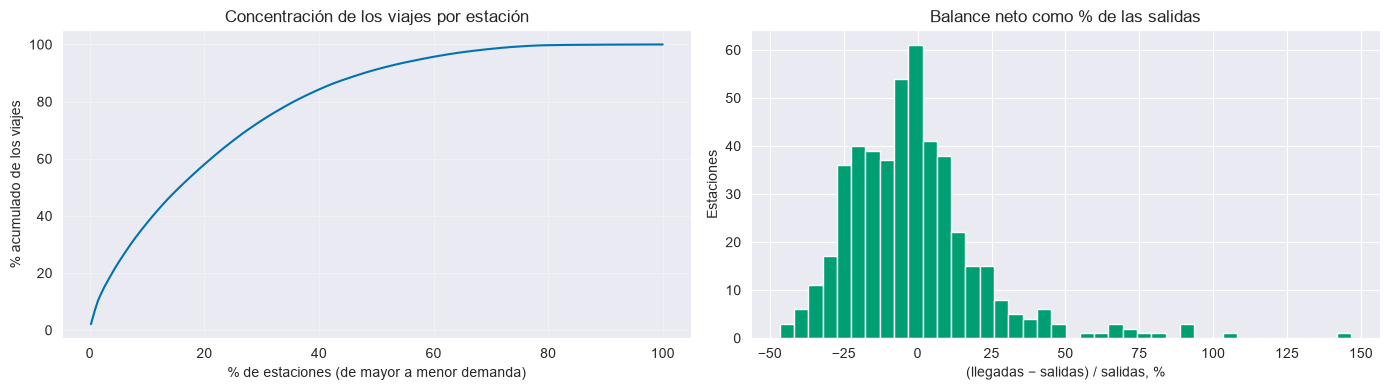

In [20]:
# Concentración de la demanda y distribución del balance neto
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))

acumulado = orden.cumsum() / orden.sum() * 100
ejes[0].plot(np.arange(1, len(acumulado) + 1) / len(acumulado) * 100, acumulado.to_numpy(), color=AZUL)
ejes[0].set_title("Concentración de los viajes por estación")
ejes[0].set_xlabel("% de estaciones (de mayor a menor demanda)")
ejes[0].set_ylabel("% acumulado de los viajes")
ejes[0].grid(alpha=0.3)

estaciones["neto_%"].plot.hist(bins=40, ax=ejes[1], color=VERDE)
ejes[1].set_title("Balance neto como % de las salidas")
ejes[1].set_xlabel("(llegadas − salidas) / salidas, %")
ejes[1].set_ylabel("Estaciones")

plt.tight_layout()
plt.show()

In [21]:
# Estaciones con mayor desbalance neto y relación entre demanda y capacidad
con_capacidad = estaciones[estaciones["dpcapacity"] > 0]
print("Mayor acumulación de bicis (neto positivo):")
display(estaciones.sort_values("neto", ascending=False).head(5)[["name", "salidas", "llegadas", "neto", "neto_%"]])
print("Mayor pérdida de bicis (neto negativo):")
display(estaciones.sort_values("neto").head(5)[["name", "salidas", "llegadas", "neto", "neto_%"]])

correlacion = con_capacidad["salidas"].corr(con_capacidad["dpcapacity"], method="spearman")
print(f"Correlación de Spearman entre salidas y capacidad: {correlacion:.2f}")
print(f"Estaciones con |neto| mayor al 10% de sus salidas: {int((estaciones['neto_%'].abs() > 10).sum())}")

Mayor acumulación de bicis (neto positivo):


,name,salidas,llegadas,neto,neto_%
51,(GDL-049) Lopez Cotilla / Penitenciaría,567876,716503,148627,26.2
34,(GDL-032) C. Degollado / Av. Miguel Hidalgo,209897,277724,67827,32.3
35,(GDL-033) Av. Hidalgo / C. Pedro Loza,408005,466216,58211,14.3
260,(GDL-187) Av. 16 de Septiembre / C. Priscilia,247898,303756,55858,22.5
56,(GDL-054) Av. Juárez / Calz. Independencia,195485,242905,47420,24.3


Mayor pérdida de bicis (neto negativo):


,name,salidas,llegadas,neto,neto_%
194,(GDL-127) Av. Vallarta / Av. de Los Arcos,262419,164389,-98030,-37.4
196,(GDL-129) C. Lope de Vega / Av. Vallarta,169178,135220,-33958,-20.1
197,(GDL-130) C. J. Ruíz de Alarcón / Av Vallarta,114284,84720,-29564,-25.9
11,(GDL-009) Calz. Federalismo/ C. J. Angulo,403873,374832,-29041,-7.2
195,(GDL-128) Av. Morelos / C. Emilio Castelar,96429,67481,-28948,-30.0


Correlación de Spearman entre salidas y capacidad: -0.02
Estaciones con |neto| mayor al 10% de sus salidas: 273


**Observaciones de la demanda y el balance por estación:**
- **Concentración:** 475 estaciones con viajes; la mediana es 31,587 salidas por estación y el máximo 567,876 (GDL-049 Lopez Cotilla / Penitenciaría, capacidad 39). El 10 % de las estaciones (48) concentra el 37.8 % de los viajes. 74 estaciones (15.6 %) tienen menos de 1,000 salidas en seis años y nueve meses; probablemente sean estaciones nuevas o retiradas, lo que se debe verificar con su primera y última fecha activa antes de decidir su tratamiento.
- **Balance neto:** 273 de las 475 estaciones (57.5 %) tienen un balance mayor al 10 % de sus salidas, positivo o negativo, acumulado en el periodo. Las que más acumulan bicicletas están en el centro (GDL-049 con +148,627, +26.2 %; GDL-032 Degollado/Hidalgo con +32.3 %). Las que más pierden están sobre Av. Vallarta (GDL-127 con −98,030, −37.4 %; GDL-129, GDL-130 y GDL-128 con −20.1 % a −30.0 %). Es un patrón geográfico consistente, y es justo el desbalance que el rebalanceo debe compensar. El EDA no observa los traslados que ya hace la operación.
- **Capacidad:** la correlación de Spearman entre salidas y capacidad es −0.02: la capacidad instalada no sigue a la demanda. Hay estaciones de capacidad 15 con 408,005 salidas (GDL-033) y otras de capacidad 39 con 567,876. Un mismo desbalance absoluto pesa muy distinto según la estación.
- **Implicación para P1, P2 y P3:** en P1 el error debe reportarse por estación y no solo en total, porque el 10 % de las estaciones domina el volumen. En P2 el balance debe normalizarse por capacidad (`neto_sobre_capacidad`), no usarse en valores absolutos. En P3, el desbalance y la ubicación son señales de agrupamiento y las estaciones con menos de 1,000 salidas deben filtrarse antes de agrupar.

## Paso 3: Limpieza, partición y preprocesamiento

En este paso se convierten los hallazgos del EDA en reglas explícitas, se separan los datos en conjuntos temporales y se dejan listas las tablas para el modelado. Se sigue el orden del pipeline (`references/pipeline-ml.md`):
1. **Limpieza** (3.1 y 3.2): cada regla se justifica con una cifra del EDA. La aplica `dataset.limpiar`, que registra cuántos registros retira cada una; el notebook la verifica.
2. **Partición** (3.3): temporal, con una brecha de 24 horas entre conjuntos para que ninguna etiqueta use datos del conjunto siguiente.
3. **Preprocesamiento** (3.4): tabla de estaciones calculada solo con entrenamiento y tabla de demanda por estación-hora, la base de P1 y P2.

**Principio:** nada de lo que se calcule con validación o prueba puede influir en una decisión de limpieza o de preprocesamiento.

### 3.1 Decisiones de limpieza

| Hallazgo (sección 2.2) | Decisión | Justificación |
|---|---|---|
| 758 filas completas repetidas | **Eliminar** (conservar una) | Son idénticas en todas las columnas; no hay conflictos que resolver |
| 3,961 viajes con origen o destino sin nomenclatura | **Excluir** | Sin capacidad ni ubicación no se pueden usar en P2 ni P3; son el 0.015 % |
| 55,035 viajes con duración cero | **Excluir** | Probable desbloqueo fallido: no es un traslado. Su sensibilidad se medirá al modelar |
| 159 viajes de más de 24 h (máximo 469 h) | **Excluir** | La hora de llegada no es real; distorsionaría el balance neto de P2 |
| Viajes de 1 a 24 h | **Conservar** | El 99.9 % dura menos de 59 min; la cola moderada es plausible y no afecta los conteos |
| Nulos en `genero` (0.51 %) y `anio_de_nacimiento` (0.13 %) | **No imputar; descartar las columnas** | Ninguna pregunta las usa y son datos personales (minimización) |
| `usuario_id` | **Descartar** | Dato personal y las preguntas son por estación, no por persona |
| Años de nacimiento imposibles | **Sin acción** | Se descartan junto con la columna |
| Meses sin datos (ninguno con los 81 meses publicados) | **No imputar; excluir esas horas de la tabla de demanda** | Rellenar con ceros inventaría una demanda nula que no ocurrió |
| Horas 1:00 a 4:59 sin servicio | **Excluir de la tabla de demanda** | Son horas cerradas, no demanda cero medida |
| 4 estaciones con capacidad 0 | **Conservar los viajes; marcar la estación** | Sirven para P1; se excluyen solo de P2 |

In [22]:
# Limpieza común: la aplica dataset.limpiar y deja el resultado en data/processed/.
# El log de esa función (abajo) es la bitácora: cuántos registros retira cada regla, en orden.
dataset.limpiar(MES_INICIO, MES_FIN)
limpios = pd.read_parquet(RUTA_VIAJES_LIMPIOS)

# Para el modelado se conservan solo las columnas que usan las tres preguntas
COLUMNAS_MODELADO = ["viaje_id", "inicio_del_viaje", "fin_del_viaje", "origen_id", "destino_id",
                     "duracion_min", "periodo_archivo"]
limpios["duracion_min"] = (limpios["fin_del_viaje"] - limpios["inicio_del_viaje"]).dt.total_seconds() / 60
limpios = limpios[COLUMNAS_MODELADO]   # usuario_id, genero y anio_de_nacimiento no pasan

2026-10-15 21:25:34.147 | INFO     | tc5061_proyecto_equipo07.dataset:limpiar:259 - Filas duplicadas (copias exactas): 758 retirados
2026-10-15 21:25:34.240 | INFO     | tc5061_proyecto_equipo07.dataset:limpiar:259 - Origen o destino sin nomenclatura: 3961 retirados
2026-10-15 21:25:34.290 | INFO     | tc5061_proyecto_equipo07.dataset:limpiar:259 - Duración cero: 55034 retirados
2026-10-15 21:25:34.339 | INFO     | tc5061_proyecto_equipo07.dataset:limpiar:259 - Duración mayor a 24 horas: 159 retirados
2026-10-15 21:25:35.038 | INFO     | tc5061_proyecto_equipo07.dataset:limpiar:266 - Años de nacimiento inválidos anulados: 3345
2026-10-15 21:25:38.249 | SUCCESS  | tc5061_proyecto_equipo07.dataset:limpiar:272 - viajes_limpios_2020-01_2026-09.parquet: 27026645 registros (59912 retirados)


In [23]:
# Validación de la limpieza: ninguna regla debe quedar sin cumplirse
assert limpios["viaje_id"].is_unique, "quedan viaje_id repetidos"
assert limpios["origen_id"].isin(ids_nomenclatura).all() and limpios["destino_id"].isin(ids_nomenclatura).all()
assert limpios["duracion_min"].between(0, DURACION_MAXIMA_MIN, inclusive="right").all()
assert limpios[["inicio_del_viaje", "fin_del_viaje", "origen_id", "destino_id"]].notna().all().all()

retirados = len(viajes) - len(limpios)
print(f"Registros originales : {len(viajes):,}")
print(f"Registros limpios    : {len(limpios):,}")
print(f"Retirados            : {retirados:,} ({retirados / len(viajes):.3%})")

# El dataset limpio ya lo guardó dataset.limpiar (CCDS: datos procesados)
print(f"Archivo: {RUTA_VIAJES_LIMPIOS.relative_to(PROJ_ROOT)} "
      f"({RUTA_VIAJES_LIMPIOS.stat().st_size / 1024**2:.1f} MB)")

# Se libera la memoria del dataset sin limpiar; el resto del notebook usa solo `limpios`
del viajes

Registros originales : 27,086,557
Registros limpios    : 27,026,645
Retirados            : 59,912 (0.221%)
Archivo: data/processed/viajes_limpios_2020-01_2026-09.parquet (540.9 MB)


**Observaciones de la limpieza:**
- **Registros retirados:** 59,912 de 27,086,557 (0.221 %); quedan 27,026,645. Por regla: 758 duplicados (0.003 %), 3,961 sin nomenclatura (0.015 %), 55,034 de duración cero (0.203 %) y 159 de más de 24 h (0.001 %). La duración cero cuenta 55,034 y no 55,035 como en 2.2 porque un viaje ya había salido por una regla anterior; el log es secuencial.
- **Regla con más impacto:** la duración cero explica el 91.9 % de lo retirado. Es la única decisión con un costo apreciable, y es la que se someterá a prueba de sensibilidad en el modelado (con y sin esos viajes).
- **Validación:** las cuatro verificaciones pasan (`viaje_id` único, estaciones con nomenclatura, duración en (0, 24 h] y sin nulos en fechas ni estaciones). El dataset limpio lo guardó `dataset.limpiar` en `data/processed/viajes_limpios_2020-01_2026-09.parquet`.
- **Lo que no se hizo:** no se imputó ningún valor, no se recortaron duraciones entre 1 y 24 h y no se rellenó ningún mes (con los 81 meses no hay hueco). `usuario_id`, `genero` y `anio_de_nacimiento` no pasan al dataset de modelado: el archivo de `data/processed/` las conserva (con los años de nacimiento imposibles anulados) y este notebook las descarta al seleccionar `COLUMNAS_MODELADO`.

### 3.2 Partición temporal

La partición es **temporal**: el entrenamiento ocupa el periodo más antiguo, la validación el siguiente y la prueba el más reciente. Una partición aleatoria mezclaría días vecinos entre conjuntos y el modelo vería, durante el entrenamiento, información de los días que luego debería predecir.

| Conjunto | Periodo | Para qué se usa |
|---|---|---|
| **train** | 2020-01-01 a 2024-09-30 | Ajustar modelos y calcular todo parámetro de preprocesamiento |
| **valid** | 2024-10-01 a 2025-09-30 | Elegir hiperparámetros y umbrales |
| **test** | 2025-10-01 a 2026-09-30 | Evaluación final, una sola vez |

Los bloques de validación y prueba duran 12 meses para que cada uno cubra las cuatro estaciones del año. Las **24 horas previas a cada frontera** quedan en un conjunto `brecha` que no se usa: una etiqueta de P1 mira hasta 24 horas adelante, y sin la brecha los últimos registros de un conjunto tendrían etiquetas calculadas con datos del siguiente.

In [24]:
# Fronteras de la partición temporal y brecha entre conjuntos
FRONTERA_VALID = pd.Timestamp("2024-10-01")
FRONTERA_TEST = pd.Timestamp("2025-10-01")
BRECHA = pd.Timedelta(hours=24)

def asignar_particion(marcas_de_tiempo):
    """Regresa train, valid, test o brecha según el instante de inicio."""
    condiciones = [marcas_de_tiempo < FRONTERA_VALID - BRECHA,
                   marcas_de_tiempo < FRONTERA_VALID,
                   marcas_de_tiempo < FRONTERA_TEST - BRECHA,
                   marcas_de_tiempo < FRONTERA_TEST]
    return pd.Series(np.select(condiciones, ["train", "brecha", "valid", "brecha"], default="test"),
                     index=marcas_de_tiempo.index).astype(
        pd.CategoricalDtype(["train", "valid", "test", "brecha"]))

limpios["particion"] = asignar_particion(limpios["inicio_del_viaje"])

resumen_particion = limpios.groupby("particion", observed=True).agg(
    viajes=("viaje_id", "size"),
    primer_viaje=("inicio_del_viaje", "min"),
    ultimo_viaje=("inicio_del_viaje", "max"),
)
resumen_particion["% de los viajes"] = (resumen_particion["viajes"] / len(limpios) * 100).round(1)
resumen_particion

,viajes,primer_viaje,ultimo_viaje,% de los viajes
particion,,,,
train,17987077,2020-01-01 06:02:20,2024-09-29 23:59:00,66.6
valid,4520744,2024-10-01 00:00:00,2025-09-29 23:59:17,16.7
test,4489362,2025-10-01 00:00:26,2026-09-30 23:59:48,16.6
brecha,29462,2024-09-30 00:00:00,2025-09-30 23:59:53,0.1


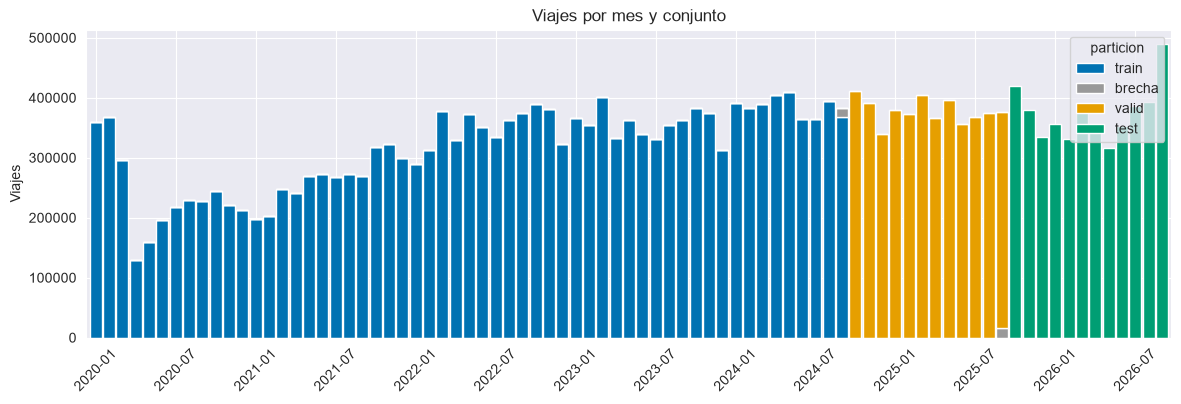

In [25]:
# Validación de la partición: orden temporal estricto y sin superposición
por_conjunto = limpios.groupby("particion", observed=True)["inicio_del_viaje"].agg(["min", "max"])
assert por_conjunto.loc["train", "max"] < por_conjunto.loc["valid", "min"]
assert por_conjunto.loc["valid", "max"] < por_conjunto.loc["test", "min"]
assert (limpios["particion"] != "brecha").sum() + (limpios["particion"] == "brecha").sum() == len(limpios)

# Viajes por mes, coloreados por conjunto
mensual_particion = (limpios.groupby(["periodo_archivo", "particion"], observed=True).size()
                     .unstack(fill_value=0)[["train", "brecha", "valid", "test"]])
mensual_particion.index = mensual_particion.index.astype(str)   # texto AAAA-MM: un índice con frecuencia mensual rompe el gráfico de pandas

ax = mensual_particion.plot.bar(stacked=True, figsize=(14, 4), width=0.9,
                                color=[AZUL, "#999999", NARANJA, VERDE])
ax.set_xticks(range(0, len(mensual_particion), 6))
ax.set_xticklabels(mensual_particion.index[::6], rotation=45)
ax.set_title("Viajes por mes y conjunto")
ax.set_xlabel("")
ax.set_ylabel("Viajes")
plt.show()

**Observaciones de la partición:**
- **Tamaño de los conjuntos:** train 17,987,077 viajes (66.6 %), valid 4,520,744 (16.7 %) y test 4,489,362 (16.6 %). Valid y test son casi del mismo tamaño, lo que hace comparables sus métricas.
- **Brecha:** 29,462 viajes (0.1 %) quedan fuera, las 24 horas previas a 2024-10-01 y a 2025-10-01. El costo en datos es despreciable.
- **Cobertura estacional:** valid (2024-10 a 2025-09) y test (2025-10 a 2026-09) cubren cada uno 12 meses completos, así que incluyen las cuatro estaciones del año. Train abarca 2020-01 a 2024-09 sin huecos.
- **Riesgo:** train contiene el choque de la pandemia (2020) y test no; la diferencia de régimen puede mejorar o empeorar el error por razones ajenas al modelo. Además, 2026-09 (490,056 viajes, el máximo de la serie) cae en test y sigue sin verificarse.

### 3.3 Preprocesamiento

Se preparan dos tablas que reutilizarán los modelos:
- **Tabla de estaciones** (`estaciones_train`): capacidad, ubicación y actividad, calculada **solo con el entrenamiento**. Es la que usará P3 y la que define el nivel base de cada estación en P1.
- **Demanda por estación-hora** (`demanda_estacion_hora`): viajes que inician en cada estación y hora, con tres reglas para no inventar datos:
  1. Los ceros comienzan en la **primera hora activa** de cada estación; antes de abrir no hay demanda cero, no hay estación.
  2. Se excluyen las horas de **1:00 a 4:59**, en las que el servicio no opera.
  3. Se excluyen las horas de los meses **sin datos** (`MESES_SIN_DATOS`, sección 1.2; ninguno con los 81 meses publicados).

In [26]:
# Tabla de estaciones calculada solo con el conjunto de entrenamiento
entrenamiento = limpios[limpios["particion"] == "train"]
actividad = pd.DataFrame({
    "salidas_train": entrenamiento["origen_id"].value_counts(),
    "llegadas_train": entrenamiento["destino_id"].value_counts(),
})
estaciones_train = (nomenclatura.set_index("id")[["name", "latitude", "longitude", "dpcapacity"]]
                    .join(actividad).fillna({"salidas_train": 0, "llegadas_train": 0}))
estaciones_train[["salidas_train", "llegadas_train"]] = estaciones_train[["salidas_train", "llegadas_train"]].astype(int)
estaciones_train["neto_train"] = estaciones_train["llegadas_train"] - estaciones_train["salidas_train"]
estaciones_train["capacidad_cero"] = estaciones_train["dpcapacity"] == 0
estaciones_train["activa_en_train"] = estaciones_train["salidas_train"] > 0

print("Estaciones en la nomenclatura          :", len(estaciones_train))
print("Con salidas en entrenamiento           :", int(estaciones_train["activa_en_train"].sum()))
print("Sin viajes en entrenamiento (nuevas)   :", int((~estaciones_train["activa_en_train"]).sum()))
print("Con capacidad 0 (fuera de P2)          :", int(estaciones_train["capacidad_cero"].sum()))
print("Con menos de 1,000 salidas en train    :", int((estaciones_train["salidas_train"] < 1000).sum()))

estaciones_train.to_parquet(PROCESSED_DATA_DIR / "estaciones_train.parquet")
estaciones_train.sort_values("salidas_train", ascending=False).head()

Estaciones en la nomenclatura          : 484
Con salidas en entrenamiento           : 363
Sin viajes en entrenamiento (nuevas)   : 121
Con capacidad 0 (fuera de P2)          : 4
Con menos de 1,000 salidas en train    : 122


,name,latitude,longitude,dpcapacity,salidas_train,llegadas_train,neto_train,capacidad_cero,activa_en_train
id,,,,,,,,,
51,(GDL-049) Lopez Cotilla / Penitenciaría,20.674140,-103.355535,39,381531,486697,105166,False,True
271,(GDL-198) Av. Alcalde / C. Hospital,20.685040,-103.347960,31,277509,267748,-9761,False,True
11,(GDL-009) Calz. Federalismo/ C. J. Angulo,20.682077,-103.353835,23,271941,252537,-19404,False,True
35,(GDL-033) Av. Hidalgo / C. Pedro Loza,20.677419,-103.347983,15,259208,290058,30850,False,True
52,(GDL-050) C.Pedro Moreno /Federalismo,20.675746,-103.354579,23,248683,247689,-994,False,True


In [27]:
# Demanda por estación-hora: conteo de viajes y rejilla completa desde la primera hora activa
limpios["hora_inicio"] = limpios["inicio_del_viaje"].dt.floor("h")
demanda = (limpios.groupby(["origen_id", "hora_inicio"], observed=True).size()
           .rename("viajes").reset_index())

# Horas válidas: dentro del rango, con servicio y en meses con datos (MESES_SIN_DATOS, de la sección 1.2)
ultima_hora = pd.Timestamp(MES_FIN + "-01") + pd.offsets.MonthEnd(0) + pd.Timedelta(hours=23)
horas = pd.date_range(f"{MES_INICIO}-01", ultima_hora, freq="h")
meses_hora = horas.strftime("%Y-%m")
horas_validas = horas[~horas.hour.isin([1, 2, 3, 4]) & ~np.isin(meses_hora, MESES_SIN_DATOS)]

# Rejilla: para cada estación, todas las horas válidas desde su primera hora con viajes
primera_hora = demanda.groupby("origen_id")["hora_inicio"].min()
ids, instantes = [], []
for estacion, primera in primera_hora.items():
    posicion = horas_validas.searchsorted(primera)
    ids.append(np.full(len(horas_validas) - posicion, estacion, dtype="int32"))
    instantes.append(horas_validas[posicion:].to_numpy())
rejilla = pd.DataFrame({"origen_id": np.concatenate(ids), "hora_inicio": np.concatenate(instantes)})

demanda_estacion_hora = rejilla.merge(demanda.astype({"origen_id": "int32"}), on=["origen_id", "hora_inicio"], how="left")
demanda_estacion_hora["viajes"] = demanda_estacion_hora["viajes"].fillna(0).astype("int16")
demanda_estacion_hora["particion"] = asignar_particion(demanda_estacion_hora["hora_inicio"])

excluidos = int(len(demanda) - demanda.merge(rejilla, on=["origen_id", "hora_inicio"]).shape[0])
print(f"Estaciones en la rejilla        : {demanda_estacion_hora['origen_id'].nunique()}")
print(f"Filas estación-hora             : {len(demanda_estacion_hora):,}")
print(f"Horas sin viajes (ceros)        : {(demanda_estacion_hora['viajes'] == 0).mean():.1%}")
print(f"Estación-horas con viajes fuera de la rejilla: {excluidos:,}")
print(f"Viajes totales en la rejilla    : {int(demanda_estacion_hora['viajes'].sum()):,}")
print(f"Viajes limpios                  : {len(limpios):,}")

demanda_estacion_hora.to_parquet(PROCESSED_DATA_DIR / "demanda_estacion_hora.parquet", index=False)
demanda_estacion_hora.groupby("particion", observed=True)["viajes"].describe().round(2)

Estaciones en la rejilla        : 472
Filas estación-hora             : 16,179,853
Horas sin viajes (ceros)        : 44.2%
Estación-horas con viajes fuera de la rejilla: 183
Viajes totales en la rejilla    : 27,026,452
Viajes limpios                  : 27,026,645


,count,mean,std,min,25%,50%,75%,max
particion,,,,,,,,
train,10566662.0,1.70,2.64,0.0,0.0,1.0,2.0,91.0
valid,2690762.0,1.68,2.68,0.0,0.0,1.0,2.0,207.0
test,2907729.0,1.54,2.66,0.0,0.0,1.0,2.0,149.0
brecha,14700.0,2.00,2.94,0.0,0.0,1.0,3.0,59.0


**Observaciones del preprocesamiento:**
- **Estaciones:** de las 484 de la nomenclatura, 363 tienen viajes en entrenamiento y 121 no: 109 aparecen después de 2024-09 (todas con viajes en test) y 12 no registran ningún viaje en todo el periodo. Cuatro tienen capacidad 0 y 122 tienen menos de 1,000 salidas en train.
- **Demanda estación-hora:** 16,179,853 filas para 472 estaciones, con 27,026,452 viajes. Se excluyeron 193 viajes (183 estación-horas) que caen en horas de 1:00 a 4:59. La rejilla arranca en la primera hora activa de cada estación, por lo que ninguna estación tiene ceros antes de existir.
- **Dispersión:** el 44.2 % de las estación-horas no tiene viajes; la mediana es 1 y la media 1.70 en train. Es una variable de conteo con muchos ceros, lo que respalda el objetivo Poisson y obliga a comparar contra el baseline en MAE, porque predecir cero ya acierta casi la mitad de las veces. Se revisará el máximo de 207 viajes en una estación-hora de validación.
- **Estaciones nuevas (hallazgo):** 109 estaciones no tienen historia en train y aparecen en test, donde generan 168,386 viajes (3.8 %). Esto baja la media de test (1.54 contra 1.70) y sube su proporción de ceros (46.5 % contra 43.8 %) sin que la demanda haya cambiado. Para ellas `demanda_media_estacion` no existe.
- **Pendiente:** definir el tratamiento de las estaciones nuevas en P1: un indicador `estacion_nueva`, un nivel base tomado de la capacidad o de la zona y una métrica que las reporte aparte. Para P3, las estaciones sin historia en train quedan fuera del agrupamiento y se asignan después al grupo más cercano.

## Paso 4 - P3 - Clustering: modelo base

**Pregunta:** ¿qué grupos de estaciones comparten patrones de uso y dónde se ubican?
**Usuario y decisión:** planeación urbana y expansión; decide dónde ampliar capacidad, qué estaciones reubicar y qué reglas de rebalanceo aplicar por grupo.

### 4.1 Diseño del modelo base

| Elemento | Decisión |
|---|---|
| **Unidad** | Una fila por estación |
| **Datos** | Solo viajes del conjunto de **entrenamiento** (2020-01 a 2024-09), ya limpios |
| **Filtro** | Estaciones con al menos `MIN_SALIDAS_TRAIN` salidas: con pocos viajes el perfil horario es ruido |
| **Variables** | Perfil horario laboral y de fin de semana (20 horas de servicio cada uno, como proporción de las salidas de la estación), volumen diario, balance neto sobre salidas, proporción de viajes circulares y duración mediana |
| **Preparación** | Estandarización con parámetros ajustados en entrenamiento |
| **Algoritmo** | K-Means; `k` entre 2 y 10, elegido por el mayor coeficiente de silueta |
| **Evaluación** | Silueta, Davies-Bouldin, Calinski-Harabasz, estabilidad (ARI) al reasignar con el año de validación e interpretación de cada grupo |

**Qué se excluye y por qué:**
- **Latitud y longitud no entran al clustering:** si entraran, los grupos serían geográficos y no por uso. Se usan después para ubicar cada grupo.
- **Horas 1:00 a 4:59:** el servicio no opera; son columnas casi constantes.
- **Estaciones nuevas (sin historia en train):** no pueden agruparse con datos de entrenamiento. Se asignan después al grupo más cercano con la información que tengan.

Es un **baseline**: define el piso con la configuración más simple (K-Means sobre variables estandarizadas), contra el cual se compararán las alternativas (HDBSCAN, PCA previo, otro conjunto de variables).

In [28]:
# Librerías del modelado y parámetros del modelo base
import subprocess
import warnings
import hashlib
import json

from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Libera la memoria de las tablas intermedias del preprocesamiento
for nombre in ["rejilla", "demanda", "demanda_estacion_hora", "ids", "instantes", "partes"]:
    globals().pop(nombre, None)

# numpy 2.2 con Accelerate (macOS) emite RuntimeWarning falsos en matmul con datos finitos;
# la finitud se verifica con un assert más abajo
warnings.filterwarnings("ignore", category=RuntimeWarning, module="sklearn.utils.extmath")

MIN_SALIDAS_TRAIN = 1000    # estaciones con menos salidas en train no se agrupan
MIN_SALIDAS_VALID = 300     # estaciones con menos salidas en valid no entran a la prueba de estabilidad
K_MINIMO, K_MAXIMO = 2, 10
HORAS_SERVICIO = [hora for hora in range(24) if hora not in (1, 2, 3, 4)]

In [29]:
# Variables por estación a partir de los viajes de un periodo
def perfil_de_estaciones(viajes_periodo):
    """Regresa una fila por estación con su perfil horario y sus indicadores de uso."""
    inicio = viajes_periodo["inicio_del_viaje"]
    base = pd.DataFrame({
        "estacion": viajes_periodo["origen_id"].to_numpy(),
        "hora": inicio.dt.hour.to_numpy(),
        "laboral": (inicio.dt.dayofweek < 5).to_numpy(),
    })
    conteo = (base.groupby(["estacion", "laboral", "hora"]).size()
              .unstack("hora", fill_value=0).reindex(columns=HORAS_SERVICIO, fill_value=0))
    estaciones_ids = conteo.index.get_level_values("estacion").unique()

    def perfil(es_laboral, prefijo):
        bloque = conteo.xs(es_laboral, level="laboral").reindex(estaciones_ids, fill_value=0)
        proporcion = bloque.div(bloque.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
        proporcion.columns = [f"{prefijo}_h{hora:02d}" for hora in proporcion.columns]
        return proporcion

    perfiles = pd.concat([perfil(True, "lab"), perfil(False, "fin")], axis=1)

    salidas = viajes_periodo["origen_id"].value_counts()
    llegadas = viajes_periodo["destino_id"].value_counts()
    dias_activos = (pd.DataFrame({"estacion": viajes_periodo["origen_id"].to_numpy(),
                                  "dia": inicio.dt.floor("D").to_numpy()})
                    .groupby("estacion")["dia"].nunique())
    circulares = (viajes_periodo["origen_id"] == viajes_periodo["destino_id"]).groupby(
        viajes_periodo["origen_id"]).mean()
    duracion = viajes_periodo.groupby("origen_id", observed=True)["duracion_min"].median()

    indicadores = pd.DataFrame({
        "salidas": salidas,
        "log_viajes_por_dia": np.log1p(salidas / dias_activos),
        "neto_sobre_salidas": (llegadas.reindex(salidas.index).fillna(0) - salidas) / salidas,
        "prop_circulares": circulares,
        "duracion_mediana_min": duracion,
    }).reindex(estaciones_ids)
    indicadores.index = indicadores.index.astype(int)
    perfiles.index = perfiles.index.astype(int)
    return perfiles.join(indicadores)

caracteristicas_train = perfil_de_estaciones(limpios[limpios["particion"] == "train"])
caracteristicas_train = caracteristicas_train[caracteristicas_train["salidas"] >= MIN_SALIDAS_TRAIN]

COLUMNAS_MODELO = [c for c in caracteristicas_train.columns if c != "salidas"]
X_train = caracteristicas_train[COLUMNAS_MODELO]

print("Estaciones agrupadas (>= %d salidas en train): %d" % (MIN_SALIDAS_TRAIN, len(X_train)))
print("Variables por estación:", len(COLUMNAS_MODELO))
print("Nulos en las variables:", int(X_train.isna().sum().sum()))
X_train[["log_viajes_por_dia", "neto_sobre_salidas", "prop_circulares", "duracion_mediana_min"]].describe().T.round(3)

Estaciones agrupadas (>= 1000 salidas en train): 362
Variables por estación: 44
Nulos en las variables: 0


,count,mean,std,min,25%,50%,75%,max
log_viajes_por_dia,362.0,3.166714,0.77968,1.447176,2.548877,3.177078,3.748612,5.398296
neto_sobre_salidas,362.0,-0.002027,0.250182,-0.458407,-0.179012,-0.029256,0.104986,1.417283
prop_circulares,362.0,0.078694,0.02499,0.033106,0.063084,0.075096,0.086465,0.303059
duracion_mediana_min,362.0,9.792703,2.066125,3.983333,8.604167,9.633333,11.0,17.516667


### 4.2 Entrenamiento y elección de `k`

Se ajusta K-Means para cada `k` entre 2 y 10, con el mismo escalador (ajustado en entrenamiento) y la misma semilla. Se elige el `k` de mayor coeficiente de silueta. Se calculan además Davies-Bouldin (menor es mejor) y Calinski-Harabasz (mayor es mejor), para no depender de una sola métrica.

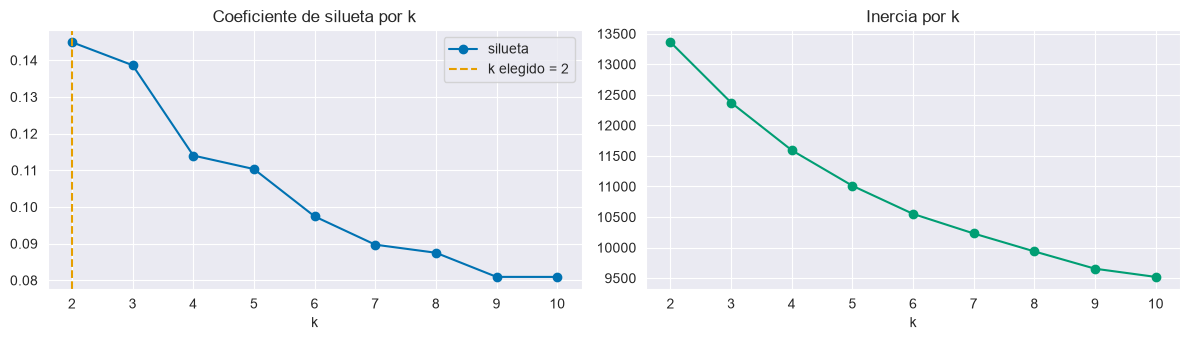

k elegido por silueta: 2


,silueta,davies_bouldin,calinski_harabasz,inercia,tam_min
k,,,,,
2,0.145,2.119,69.157,13361.263,160
3,0.139,2.265,51.590,12372.124,68
4,0.114,2.045,44.633,11592.239,22
5,0.110,1.985,39.853,11011.127,17
6,0.097,2.234,36.287,10550.767,19
7,0.090,2.026,32.950,10230.613,5
8,0.088,2.103,30.489,9937.113,17
9,0.081,2.205,28.676,9654.078,16
10,0.081,2.225,26.327,9519.917,9


In [30]:
# Ajuste de K-Means para cada k y selección por silueta
escalador = StandardScaler().fit(X_train)
Z_train = escalador.transform(X_train)
assert np.isfinite(Z_train).all(), "variables escaladas con valores no finitos"

resultados_k = []
for k in range(K_MINIMO, K_MAXIMO + 1):
    modelo_k = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z_train)
    resultados_k.append({
        "k": k,
        "silueta": silhouette_score(Z_train, modelo_k.labels_),
        "davies_bouldin": davies_bouldin_score(Z_train, modelo_k.labels_),
        "calinski_harabasz": calinski_harabasz_score(Z_train, modelo_k.labels_),
        "inercia": modelo_k.inertia_,
        "tam_min": int(np.bincount(modelo_k.labels_).min()),
    })
resultados_k = pd.DataFrame(resultados_k).set_index("k")
K_ELEGIDO = int(resultados_k["silueta"].idxmax())

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5))
resultados_k["silueta"].plot(marker="o", ax=ejes[0], color=AZUL)
ejes[0].axvline(K_ELEGIDO, color=NARANJA, linestyle="--", label=f"k elegido = {K_ELEGIDO}")
ejes[0].set_title("Coeficiente de silueta por k")
ejes[0].set_xlabel("k")
ejes[0].legend()
resultados_k["inercia"].plot(marker="o", ax=ejes[1], color=VERDE)
ejes[1].set_title("Inercia por k")
ejes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

print("k elegido por silueta:", K_ELEGIDO)
resultados_k.round(3)

In [31]:
# Modelo base: escalador + K-Means con el k elegido (un solo objeto para registrar y reutilizar)
modelo_base = Pipeline([
    ("escalador", StandardScaler()),
    ("kmeans", KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=SEMILLA)),
]).fit(X_train)

etiquetas_train = modelo_base.named_steps["kmeans"].labels_
caracteristicas_train = caracteristicas_train.assign(grupo=etiquetas_train)

tamanos = pd.Series(etiquetas_train).value_counts().sort_index()
print("Estaciones por grupo:", tamanos.to_dict())

Estaciones por grupo: {0: 202, 1: 160}


**Observaciones del entrenamiento:**
- **Selección de `k`:** la silueta es máxima en `k = 2` (0.145) y baja al aumentar `k` (0.139 con 3, 0.114 con 4 y 0.081 con 10). Davies-Bouldin, en cambio, es mejor en `k = 5` (1.985): las métricas no coinciden y ningún `k` destaca con claridad.
- **Calidad del agrupamiento:** una silueta de 0.145 indica estructura débil: los grupos se solapan y las estaciones no forman conglomerados bien separados. Davies-Bouldin es 2.12 y Calinski-Harabasz, 69.2. Es el piso con el que se compararán las alternativas.
- **Tamaño de los grupos:** 362 estaciones agrupadas (las otras 122 de la nomenclatura tienen menos de 1,000 salidas en train o ninguna). Con `k = 2` quedan 202 y 160 estaciones; desde `k = 4` aparecen grupos de 22 estaciones o menos (5 con `k = 7`), poco útiles para decidir.

### 4.3 Evaluación

Además de las métricas internas, se evalúan dos cosas que importan para planeación:
- **Estabilidad:** ¿los grupos se sostienen en otro periodo? Se calculan las mismas variables con los viajes del año de **validación** (2024-10 a 2025-09), se asigna cada estación al grupo más cercano con el modelo ajustado en entrenamiento y se compara con su grupo original (índice de Rand ajustado: 1 = idéntico, 0 = azar).
- **Interpretabilidad:** un grupo solo sirve si se le puede nombrar; se describe su perfil horario y su ubicación.

In [32]:
# Estabilidad: reasignación de las estaciones con las variables calculadas en el año de validación
caracteristicas_valid = perfil_de_estaciones(limpios[limpios["particion"] == "valid"])
caracteristicas_valid = caracteristicas_valid[caracteristicas_valid["salidas"] >= MIN_SALIDAS_VALID]
comunes = caracteristicas_train.index.intersection(caracteristicas_valid.index)

grupo_original = caracteristicas_train.loc[comunes, "grupo"]
grupo_en_valid = modelo_base.predict(caracteristicas_valid.loc[comunes, COLUMNAS_MODELO])
ari_valid = adjusted_rand_score(grupo_original, grupo_en_valid)

# Métricas internas del modelo elegido
fila_elegida = resultados_k.loc[K_ELEGIDO]
metricas = {
    "silueta": float(fila_elegida["silueta"]),
    "davies_bouldin": float(fila_elegida["davies_bouldin"]),
    "calinski_harabasz": float(fila_elegida["calinski_harabasz"]),
    "inercia": float(fila_elegida["inercia"]),
    "ari_valid": float(ari_valid),
    "estaciones_train": int(len(X_train)),
    "estaciones_estabilidad": int(len(comunes)),
    "estaciones_cambian_de_grupo": int((grupo_original.to_numpy() != grupo_en_valid).sum()),
    "tam_grupo_min": int(tamanos.min()),
    "tam_grupo_max": int(tamanos.max()),
}
pd.Series(metricas).to_frame("valor")

,valor
silueta,0.144915
davies_bouldin,2.119360
calinski_harabasz,69.157043
inercia,13361.262717
ari_valid,0.656071
estaciones_train,362.000000
estaciones_estabilidad,359.000000
estaciones_cambian_de_grupo,34.000000
tam_grupo_min,160.000000
tam_grupo_max,202.000000


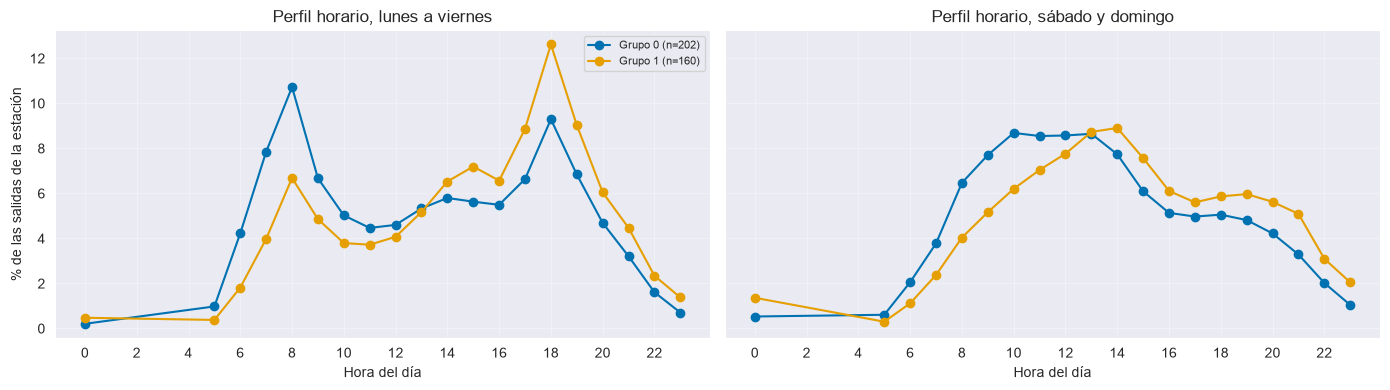

,estaciones,salidas_medianas,viajes_por_dia,neto_sobre_salidas,prop_circulares,duracion_mediana_min,capacidad_mediana
grupo,,,,,,,
0,202,26236.0,19.841,0.029,0.08,9.625,15.0
1,160,51004.0,29.422,-0.093,0.071,9.633,15.0


In [33]:
# Interpretación: perfil horario medio por grupo y características de cada grupo
columnas_lab = [c for c in COLUMNAS_MODELO if c.startswith("lab_")]
columnas_fin = [c for c in COLUMNAS_MODELO if c.startswith("fin_")]
horas = HORAS_SERVICIO
colores = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#999999",
           "#000000", "#882255"]

fig, ejes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for grupo in range(K_ELEGIDO):
    miembros = caracteristicas_train["grupo"] == grupo
    ejes[0].plot(horas, caracteristicas_train.loc[miembros, columnas_lab].mean() * 100,
                 marker="o", color=colores[grupo], label=f"Grupo {grupo} (n={int(miembros.sum())})")
    ejes[1].plot(horas, caracteristicas_train.loc[miembros, columnas_fin].mean() * 100,
                 marker="o", color=colores[grupo])
ejes[0].set_title("Perfil horario, lunes a viernes")
ejes[1].set_title("Perfil horario, sábado y domingo")
for eje in ejes:
    eje.set_xlabel("Hora del día")
    eje.set_xticks(range(0, 24, 2))
    eje.grid(alpha=0.3)
ejes[0].set_ylabel("% de las salidas de la estación")
ejes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

resumen_grupos = (caracteristicas_train
                  .join(nomenclatura.set_index("id")[["dpcapacity", "latitude", "longitude"]])
                  .groupby("grupo")
                  .agg(estaciones=("salidas", "size"),
                       salidas_medianas=("salidas", "median"),
                       viajes_por_dia=("log_viajes_por_dia", lambda s: np.expm1(s).median()),
                       neto_sobre_salidas=("neto_sobre_salidas", "median"),
                       prop_circulares=("prop_circulares", "median"),
                       duracion_mediana_min=("duracion_mediana_min", "median"),
                       capacidad_mediana=("dpcapacity", "median"))
                  .round(3))
resumen_grupos

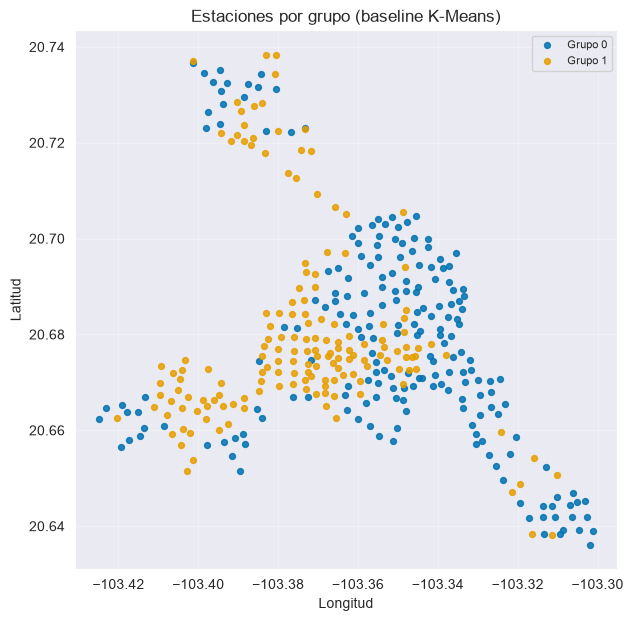

In [34]:
# Ubicación de las estaciones por grupo
mapa = caracteristicas_train.join(nomenclatura.set_index("id")[["name", "latitude", "longitude"]])

fig, ax = plt.subplots(figsize=(7, 7))
for grupo in range(K_ELEGIDO):
    miembros = mapa["grupo"] == grupo
    ax.scatter(mapa.loc[miembros, "longitude"], mapa.loc[miembros, "latitude"], s=18,
               color=colores[grupo], label=f"Grupo {grupo}", alpha=0.85)
ax.set_title("Estaciones por grupo (baseline K-Means)")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

**Observaciones de la evaluación:**
- **Métricas internas:** silueta 0.145, Davies-Bouldin 2.12, Calinski-Harabasz 69.2 e inercia 13,361 para `k = 2`.
- **Estabilidad:** el índice de Rand ajustado entre el grupo de entrenamiento y el reasignado con el año de validación es **0.66** sobre 359 estaciones comunes; 34 (9.5 %) cambian de grupo. La división es moderadamente estable, aunque no inmune al periodo.
- **Interpretación:** el grupo 0 (202 estaciones) tiene un pico matutino dominante a las 8:00 (10.7 % de sus salidas laborales) y su pico de fin de semana a las 10:00; el grupo 1 (160) tiene su pico a las 18:00 (12.6 %). El grupo 1 mueve más viajes (mediana de 29.4 viajes por día contra 19.8) y tiende a perder bicicletas (balance −9.3 % de sus salidas contra +2.9 %). Duración mediana (9.63 min en ambos), proporción de viajes circulares (8.0 % y 7.1 %) y capacidad (15) casi no los distinguen. Las etiquetas 0 y 1 de K-Means son arbitrarias: con los 81 meses quedaron invertidas respecto a una corrida anterior con 79.
- **Ubicación:** el grupo 1 (salida de tarde) está más cerca del centro de la red (distancia mediana de 2.2 km contra 3.0 km del grupo 0) y más al poniente (longitud mediana −103.373 contra −103.350). Hipótesis por verificar: el grupo 0 son estaciones desde donde se sale por la mañana (residenciales) y el grupo 1, desde donde se sale al final de la jornada (zonas de trabajo).
- **Límites del baseline:** la separación se explica casi solo por el perfil horario y el volumen; con `k = 2` la granularidad es insuficiente para decidir dónde ampliar o reubicar. Las 40 variables de perfil pesan mucho más que los 4 indicadores escalares en la distancia. Las estaciones nuevas (109) no se agrupan. Siguientes pasos: PCA o ponderación de variables, `k` de 4 a 5 revisando Davies-Bouldin, y HDBSCAN.

### 4.4 Registro en MLflow

El baseline se registra en el servidor del equipo: experimento `p3`, run `baseline`.
- **Parámetros:** modelo, `k`, semilla, filtros, periodo de entrenamiento y `data_version` (SHA-256 del manifiesto de fuentes).
- **Métricas:** silueta, Davies-Bouldin, Calinski-Harabasz, inercia, estabilidad (ARI) y tamaños de grupo; la silueta por `k` se registra como serie.
- **Etiquetas:** equipo, pregunta, tarea, autor y commit de Git.
- **Artefactos:** asignación de grupo por estación, perfiles, gráficas y el modelo (escalador + K-Means). Se suben por el proxy del servidor (`mlflow-artifacts:/p3`); también quedan en `reports/figures/`.

El experimento se crea con `artifact_location="mlflow-artifacts:/p3"`: si se crea sin esa opción, el servidor asigna una ruta local suya (`/home/ec2-user/...`) y la subida de artefactos falla.

La celda es **idempotente**: si el run `baseline` ya existe en el experimento, no crea otro, para no duplicar corridas al reejecutar el notebook. Se puede forzar uno nuevo con `REGISTRAR_DE_NUEVO = True`.

Solo se registran agregados y datos públicos de estaciones; no hay información de usuarios.

In [41]:
# Registro del baseline en MLflow (experimento p3, run baseline)
import mlflow
import mlflow.sklearn

URI_MLFLOW = "https://mlflow.equipo7mlops.com/"
EXPERIMENTO = "p3"
NOMBRE_RUN = "baseline"
REGISTRAR_EN_MLFLOW = True
REGISTRAR_DE_NUEVO = False

def commit_actual():
    try:
        return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], cwd=PROJ_ROOT, text=True).strip()
    except Exception:
        return "desconocido"

RUTA_FIGURAS = FIGURES_DIR

if not REGISTRAR_EN_MLFLOW:
    print("Registro desactivado (REGISTRAR_EN_MLFLOW = False)")
else:
    mlflow.set_tracking_uri(URI_MLFLOW)
    existentes = []
    experimento = mlflow.get_experiment_by_name(EXPERIMENTO)
    # El experimento debe guardar los artefactos por el proxy del servidor (mlflow-artifacts:/);
    # si apunta a una ruta local del servidor, el cliente no puede escribir en ella.
    if experimento is None:
        mlflow.create_experiment(EXPERIMENTO, artifact_location="mlflow-artifacts:/" + EXPERIMENTO)
        experimento = mlflow.get_experiment_by_name(EXPERIMENTO)
    assert experimento.artifact_location.startswith("mlflow-artifacts:"), (
        "El experimento no usa el proxy de artefactos: " + experimento.artifact_location)
    if experimento is not None:
        existentes = mlflow.search_runs(experiment_ids=[experimento.experiment_id],
                                        filter_string=f"tags.mlflow.runName = '{NOMBRE_RUN}'")
    if len(existentes) and not REGISTRAR_DE_NUEVO:
        print(f"Ya existe un run '{NOMBRE_RUN}' en el experimento '{EXPERIMENTO}': "
              f"{URI_MLFLOW}#/experiments/{experimento.experiment_id}/runs/{existentes.iloc[0]['run_id']}")
    else:
        # Artefactos locales: asignación por estación, perfiles, variables y gráficas
        asignacion = (mapa[["name", "latitude", "longitude", "grupo", "salidas"]]
                      .rename(columns={"name": "estacion", "salidas": "salidas_train"}))
        asignacion.to_csv(RUTA_FIGURAS / "p3_asignacion_grupos.csv", index_label="estacion_id")
        resumen_grupos.to_csv(RUTA_FIGURAS / "p3_resumen_grupos.csv")
        (RUTA_FIGURAS / "p3_variables.json").write_text(json.dumps(COLUMNAS_MODELO, ensure_ascii=False, indent=1))

        fig_k, ejes_k = plt.subplots(figsize=(6, 3.5))
        resultados_k["silueta"].plot(marker="o", ax=ejes_k, color=AZUL)
        ejes_k.axvline(K_ELEGIDO, color=NARANJA, linestyle="--")
        ejes_k.set_title("Silueta por k")
        ejes_k.set_xlabel("k")
        fig_k.tight_layout()
        fig_k.savefig(RUTA_FIGURAS / "p3_silueta_por_k.png", dpi=150)
        plt.close(fig_k)

        fig_m, eje_m = plt.subplots(figsize=(7, 7))
        for grupo in range(K_ELEGIDO):
            miembros = mapa["grupo"] == grupo
            eje_m.scatter(mapa.loc[miembros, "longitude"], mapa.loc[miembros, "latitude"], s=18,
                          color=colores[grupo], label=f"Grupo {grupo}")
        eje_m.set_title("Estaciones por grupo (baseline)")
        eje_m.legend(fontsize=8)
        fig_m.savefig(RUTA_FIGURAS / "p3_mapa_grupos.png", dpi=150)
        plt.close(fig_m)

        mlflow.set_experiment(EXPERIMENTO)
        with mlflow.start_run(run_name=NOMBRE_RUN) as corrida:
            mlflow.set_tags({
                "equipo": "7", "pregunta": "P3", "tarea": "clustering", "autor": "lasd",
                "commit": commit_actual(), "notebook": "0.03-lasd-exploracion-carga",
                "etapa": "baseline",
            })
            mlflow.log_params({
                "modelo": "StandardScaler + KMeans",
                "k": K_ELEGIDO, "k_minimo": K_MINIMO, "k_maximo": K_MAXIMO, "n_init": 10,
                "semilla": SEMILLA,
                "rango_datos": f"{MES_INICIO} a {MES_FIN}",
                "periodo_train": "2020-01-01 a 2024-09-29",
                "periodo_estabilidad": "2024-10-01 a 2025-09-29",
                "min_salidas_train": MIN_SALIDAS_TRAIN, "min_salidas_valid": MIN_SALIDAS_VALID,
                "n_variables": len(COLUMNAS_MODELO),
                "horas_excluidas": "1-4",
                "data_version": dataset.version_datos(),
            })
            for k, fila in resultados_k.iterrows():
                mlflow.log_metric("silueta_por_k", float(fila["silueta"]), step=int(k))
            mlflow.log_metrics(metricas)
            mlflow.log_artifacts(str(RUTA_FIGURAS), artifact_path="p3")
            mlflow.sklearn.log_model(modelo_base, name="modelo",
                                     input_example=X_train.head(3))
        print("Run registrado:", f"{URI_MLFLOW}#/experiments/{corrida.info.experiment_id}/runs/{corrida.info.run_id}")

/Users/lsanchez/Maestria_proyectos/MLOps-ProyectoMiBici-Equipo7/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run baseline at: https://mlflow.equipo7mlops.com/#/experiments/2/runs/f440618eac0a415bbb43f1c8d5f4bfba
🧪 View experiment at: https://mlflow.equipo7mlops.com/#/experiments/2
Run registrado: https://mlflow.equipo7mlops.com/#/experiments/2/runs/f440618eac0a415bbb43f1c8d5f4bfba


### 4.5 Modelo alternativo: PCA sobre el perfil horario + K-Means

El baseline mezcla 40 columnas de perfil horario con 4 indicadores escalares, y el perfil horario domina la distancia. Además, con `k = 2` solo separa "salidas de mañana" de "salidas de tarde". La alternativa mantiene las mismas variables y el mismo conjunto de estaciones, y cambia la representación y el número de grupos:

| Elemento | Decisión |
|---|---|
| **Datos y variables** | Los mismos del baseline (362 estaciones, 44 variables, solo entrenamiento) |
| **Representación** | Estandarización, **PCA** (3 a 10 componentes) y K-Means sobre los componentes |
| **Pesos por bloque** | Variante evaluada: cada bloque (laboral, fin de semana, indicadores) aporta la misma varianza total |
| **`k`** | De 3 a 6; no se fuerza `k = 2` |
| **Semillas** | Cada configuración se corre con 5 semillas y se compara el promedio; elegir con una sola semilla premia la suerte |
| **Comparación justa** | Silueta, Davies-Bouldin y Calinski-Harabasz se calculan en el **espacio estandarizado del baseline**, no en el espacio PCA, donde una dimensión menor "mejora" sola |

**Criterios de aceptación** (acordados antes de ver los resultados):
1. Silueta mayor que la del baseline (0.146).
2. ARI de estabilidad igual o mayor que el del baseline (0.68).
3. Tamaño mínimo de grupo de al menos 20 estaciones.
4. Cada grupo se puede nombrar con su perfil horario y su ubicación (se evalúa en 4.8).

Si no cumple, el resultado se documenta igual y el baseline sigue siendo el piso.

In [36]:
# Modelo alternativo de P3: bloques ponderados + PCA + K-Means
from sklearn.decomposition import PCA
from sklearn.preprocessing import FunctionTransformer

K_ALTERNATIVO = range(3, 7)
COMPONENTES = [3, 4, 5, 6, 8, 10]
SEMILLAS_ALTERNATIVO = [SEMILLA, 1, 2, 3, 4]
TAM_MIN_ACEPTABLE = 20

# Estaciones comunes entre entrenamiento y validación (las mismas de la prueba de estabilidad del baseline)
X_valid_comunes = caracteristicas_valid.loc[comunes, COLUMNAS_MODELO]
indice_comunes = [caracteristicas_train.index.get_loc(estacion) for estacion in comunes]


def pesos_por_bloque(columnas):
    """Peso por columna para que cada bloque (laboral, fin de semana, indicadores) aporte la misma varianza total."""
    bloque = pd.Series(["lab" if c.startswith("lab_") else "fin" if c.startswith("fin_") else "esc"
                        for c in columnas])
    return (1 / np.sqrt(bloque.map(bloque.value_counts()))).to_numpy()


def aplicar_pesos(matriz, pesos):
    return matriz * pesos


def construir_modelo(componentes, ponderar, k, semilla):
    """Escalador + pesos por bloque (opcional) + PCA + K-Means, en un solo objeto."""
    pasos = [("escalador", StandardScaler())]
    if ponderar:
        # Sin pesos no se agrega el paso: el modelo registrado no depende de funciones del notebook
        pasos.append(("pesos", FunctionTransformer(aplicar_pesos,
                                                   kw_args={"pesos": pesos_por_bloque(COLUMNAS_MODELO)})))
    pasos += [("pca", PCA(n_components=componentes, random_state=semilla)),
              ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=semilla))]
    return Pipeline(pasos)


def evaluar_modelo(modelo):
    """Métricas internas en el espacio estandarizado del baseline (Z_train), para que sean comparables."""
    etiquetas = modelo.named_steps["kmeans"].labels_
    return {
        "silueta": silhouette_score(Z_train, etiquetas),
        "davies_bouldin": davies_bouldin_score(Z_train, etiquetas),
        "calinski_harabasz": calinski_harabasz_score(Z_train, etiquetas),
        "tam_min": int(np.bincount(etiquetas).min()),
        "ari_valid": adjusted_rand_score(etiquetas[indice_comunes], modelo.predict(X_valid_comunes)),
    }


# Referencia: el baseline en el mismo espacio, para cada k (con la misma prueba de estabilidad)
filas_base = []
for k in range(K_MINIMO, K_MAXIMO + 1):
    modelo_k = Pipeline([("escalador", StandardScaler()),
                         ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=SEMILLA))]).fit(X_train)
    filas_base.append({"k": k, **evaluar_modelo(modelo_k)})
baseline_por_k = pd.DataFrame(filas_base).set_index("k")
baseline_por_k.loc[2:6].round(3)

,silueta,davies_bouldin,calinski_harabasz,tam_min,ari_valid
k,,,,,
2,0.145,2.119,69.157,160,0.656
3,0.139,2.265,51.590,68,0.689
4,0.114,2.045,44.633,22,0.576
5,0.110,1.985,39.853,17,0.586
6,0.097,2.234,36.287,19,0.426


### 4.6 Búsqueda y selección

Se prueba con y sin pesos por bloque, 6 números de componentes y `k` de 3 a 6, con 5 semillas cada una (240 ajustes). La selección usa solo configuraciones que cumplen los criterios 2 y 3; entre ellas, la de mayor silueta promedio. Nótese que el ARI de estabilidad usa el año de validación para elegir, no el de prueba, que sigue sin tocarse.

In [37]:
# Búsqueda: con y sin pesos por bloque, componentes de PCA y k; cada combinación con varias semillas
filas = []
for ponderar in (False, True):
    for componentes in COMPONENTES:
        for k in K_ALTERNATIVO:
            for semilla in SEMILLAS_ALTERNATIVO:
                modelo = construir_modelo(componentes, ponderar, k, semilla).fit(X_train)
                filas.append({"ponderar": ponderar, "componentes": componentes, "k": k,
                              "semilla": semilla, **evaluar_modelo(modelo)})
busqueda = pd.DataFrame(filas)

# Una fila por configuración: promedio entre semillas (el peor caso en el tamaño mínimo de grupo)
resumen_busqueda = (busqueda.groupby(["ponderar", "componentes", "k"])
                    .agg(silueta=("silueta", "mean"), silueta_min=("silueta", "min"),
                         davies_bouldin=("davies_bouldin", "mean"),
                         calinski_harabasz=("calinski_harabasz", "mean"),
                         ari_valid=("ari_valid", "mean"), ari_min=("ari_valid", "min"),
                         tam_min=("tam_min", "min"))
                    .reset_index())

# Selección: solo configuraciones que cumplen estabilidad y tamaño mínimo; entre ellas, la mayor silueta
cumplen = resumen_busqueda[(resumen_busqueda["tam_min"] >= TAM_MIN_ACEPTABLE)
                           & (resumen_busqueda["ari_valid"] >= metricas["ari_valid"])]
print(f"Configuraciones evaluadas: {len(resumen_busqueda)} | que cumplen ARI y tamaño mínimo: {len(cumplen)}")
reserva = cumplen if len(cumplen) else resumen_busqueda
elegido = reserva.sort_values(["silueta", "componentes"], ascending=[False, True]).iloc[0]
print("Configuración elegida:",
      {"ponderar": bool(elegido["ponderar"]), "componentes": int(elegido["componentes"]), "k": int(elegido["k"])})

reserva.sort_values("silueta", ascending=False).head(8).round(3)

Configuraciones evaluadas: 48 | que cumplen ARI y tamaño mínimo: 18
Configuración elegida: {'ponderar': False, 'componentes': 5, 'k': 3}


,ponderar,componentes,k,silueta,silueta_min,davies_bouldin,calinski_harabasz,ari_valid,ari_min,tam_min
8,False,5,3,0.140,0.139,2.223,51.458,0.676,0.639,42
0,False,3,3,0.140,0.136,2.214,51.393,0.685,0.624,36
16,False,8,3,0.139,0.136,2.243,51.405,0.686,0.667,45
4,False,4,3,0.138,0.137,2.264,51.559,0.680,0.654,65
12,False,6,3,0.138,0.137,2.269,51.575,0.676,0.648,68
20,False,10,3,0.137,0.136,2.281,51.504,0.681,0.660,65
32,True,5,3,0.116,0.109,2.358,43.273,0.658,0.630,47
28,True,4,3,0.104,0.101,2.412,42.680,0.670,0.660,73


### 4.7 Evaluación contra el baseline

In [38]:
# Modelo alternativo final (semilla del proyecto) y comparación con el baseline
modelo_alt = construir_modelo(int(elegido["componentes"]), bool(elegido["ponderar"]),
                              int(elegido["k"]), SEMILLA).fit(X_train)
etiquetas_alt = modelo_alt.named_steps["kmeans"].labels_
metricas_alt = evaluar_modelo(modelo_alt)
varianza_pca = float(modelo_alt.named_steps["pca"].explained_variance_ratio_.sum())

k_alt = int(elegido["k"])
comparacion = pd.DataFrame({
    "baseline (k=2)": baseline_por_k.loc[K_ELEGIDO],
    f"baseline (k={k_alt})": baseline_por_k.loc[k_alt],
    f"alternativo (k={k_alt}, promedio de {len(SEMILLAS_ALTERNATIVO)} semillas)": pd.Series({
        "silueta": elegido["silueta"], "davies_bouldin": elegido["davies_bouldin"],
        "calinski_harabasz": elegido["calinski_harabasz"],
        "ari_valid": elegido["ari_valid"], "tam_min": elegido["tam_min"]}),
    f"alternativo (k={k_alt}, semilla {SEMILLA})": pd.Series(metricas_alt),
}).T[["silueta", "davies_bouldin", "calinski_harabasz", "ari_valid", "tam_min"]]

# Criterios de aceptación acordados
criterios = {
    f"Silueta > baseline ({metricas['silueta']:.3f})": bool(elegido["silueta"] > metricas["silueta"]),
    f"ARI de estabilidad >= baseline ({metricas['ari_valid']:.3f})": bool(elegido["ari_valid"] >= metricas["ari_valid"]),
    f"Tamaño mínimo de grupo >= {TAM_MIN_ACEPTABLE}": bool(elegido["tam_min"] >= TAM_MIN_ACEPTABLE),
}
for nombre, cumple in criterios.items():
    print(("CUMPLE    " if cumple else "NO CUMPLE ") + nombre)
ACEPTADO = all(criterios.values())
print("\nVeredicto cuantitativo:", "ACEPTADO" if ACEPTADO else "NO ACEPTADO: el baseline sigue siendo el piso")
print(f"Varianza explicada por los {int(elegido['componentes'])} componentes: {varianza_pca:.1%}")
print(f"Silueta entre semillas: min {elegido['silueta_min']:.3f}, promedio {elegido['silueta']:.3f}")
print(f"ARI entre semillas: min {elegido['ari_min']:.3f}, promedio {elegido['ari_valid']:.3f}")
comparacion.round(3)

NO CUMPLE Silueta > baseline (0.145)
CUMPLE    ARI de estabilidad >= baseline (0.656)
CUMPLE    Tamaño mínimo de grupo >= 20

Veredicto cuantitativo: NO ACEPTADO: el baseline sigue siendo el piso
Varianza explicada por los 5 componentes: 56.2%
Silueta entre semillas: min 0.139, promedio 0.140
ARI entre semillas: min 0.639, promedio 0.676


,silueta,davies_bouldin,calinski_harabasz,ari_valid,tam_min
baseline (k=2),0.145,2.119,69.157,0.656,160.0
baseline (k=3),0.139,2.265,51.590,0.689,68.0
"alternativo (k=3, promedio de 5 semillas)",0.140,2.223,51.458,0.676,42.0
"alternativo (k=3, semilla 42)",0.139,2.265,51.590,0.675,68.0


**Observaciones de la evaluación:**
- **Selección:** de 48 configuraciones, 18 cumplen estabilidad y tamaño mínimo. Gana PCA **sin pesos por bloque**, 5 componentes (56.2 % de la varianza) y `k = 3`. Las mejores configuraciones ponderadas (silueta 0.116 y 0.104) quedan por debajo de las no ponderadas (0.137 a 0.140): igualar el peso de los bloques no ayudó en el espacio común.
- **Veredicto contra los criterios:** la silueta es **0.140 contra 0.145 y no cumple** (−0.005). El ARI de estabilidad (0.676 en promedio) y el tamaño mínimo de grupo (42) sí cumplen. Por el criterio 1, el resultado es **NO ACEPTADO** y el baseline sigue siendo el piso.
- **Sensibilidad a la semilla:** la silueta es estable (0.139 a 0.140), pero el ARI promedia 0.676 con un mínimo de 0.639 entre semillas (0.675 con la del proyecto), y el grupo más chico llega a 42 estaciones en el peor caso (68 con la del proyecto). La ventaja en estabilidad sobre el baseline (0.656) es pequeña y no concluyente. Por eso la selección usa el promedio de varias semillas y no una sola corrida.
- **A igual `k`, no hay una mejora clara:** con `k = 3` el baseline tiene silueta 0.139, Davies-Bouldin 2.265, ARI 0.689 y grupo mínimo de 68; el alternativo, 0.140, 2.223, 0.676 y 42. Mejora apenas las métricas internas, pero es menos estable y su grupo más chico es menor. Con 79 meses el alternativo sí superaba al baseline a igual `k` (ARI 0.698 contra 0.660); con los 81 meses esa ventaja desaparece, así que no era robusta a los datos.
- **Sobre el criterio 1:** compara un modelo de `k = 3` contra el de `k = 2` del baseline, y el baseline optimiza esa métrica en ese espacio; además la silueta cae al aumentar `k` (0.145, 0.139, 0.114). Si el equipo quiere `k ≥ 3` para decidir, el criterio justo es comparar a igual `k`, y con los datos actuales tampoco ahí hay ventaja clara. Esa decisión es del equipo; aquí se reporta con el criterio acordado.
- **Calidad absoluta:** una silueta de 0.14 sigue indicando estructura débil. Las estaciones forman más un continuo que grupos separados; ningún modelo de esta familia cambia eso.

### 4.8 Interpretación

Se compara el perfil horario, los indicadores y la ubicación de los tres grupos, y cómo se relacionan con los dos del baseline.

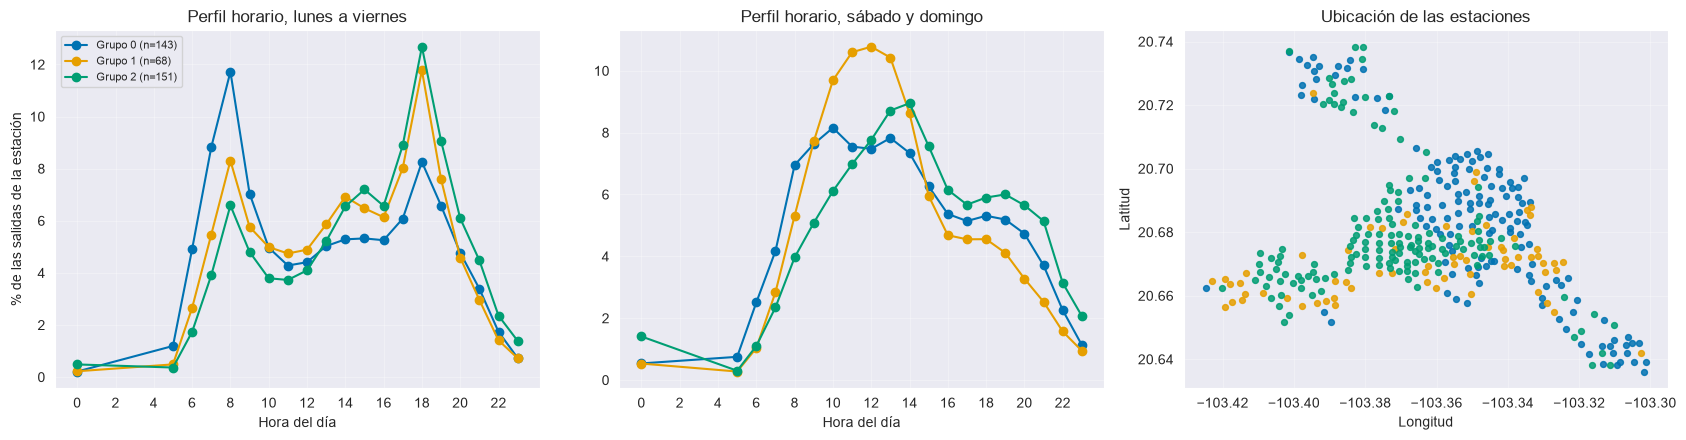

Estaciones por grupo alternativo (filas) y grupo del baseline (columnas):


grupo,0,1
grupo_alt,,
0,138,5
1,63,5
2,1,150


,estaciones,pct_salidas_6_a_9h,pct_salidas_17_a_20h,viajes_por_dia,neto_sobre_salidas,prop_circulares,duracion_mediana_min,capacidad_mediana
grupo_alt,,,,,,,,
0,143,32.011,25.638,19.907,0.045,0.076,9.300,15.0
1,68,21.655,30.097,18.685,-0.023,0.083,10.683,15.0
2,151,17.232,35.587,30.321,-0.096,0.071,9.633,15.0


In [39]:
# Interpretación: perfil horario, indicadores y ubicación de cada grupo del modelo alternativo
asignacion_alt = (caracteristicas_train.drop(columns="grupo")
                  .assign(grupo_alt=etiquetas_alt)
                  .join(nomenclatura.set_index("id")[["name", "dpcapacity", "latitude", "longitude"]]))
horas_manana = [f"lab_h{h:02d}" for h in range(6, 10)]
horas_tarde = [f"lab_h{h:02d}" for h in range(17, 21)]
asignacion_alt["pct_manana"] = asignacion_alt[horas_manana].sum(axis=1) * 100
asignacion_alt["pct_tarde"] = asignacion_alt[horas_tarde].sum(axis=1) * 100

resumen_alt = (asignacion_alt.groupby("grupo_alt")
               .agg(estaciones=("salidas", "size"),
                    pct_salidas_6_a_9h=("pct_manana", "median"),
                    pct_salidas_17_a_20h=("pct_tarde", "median"),
                    viajes_por_dia=("log_viajes_por_dia", lambda s: np.expm1(s).median()),
                    neto_sobre_salidas=("neto_sobre_salidas", "median"),
                    prop_circulares=("prop_circulares", "median"),
                    duracion_mediana_min=("duracion_mediana_min", "median"),
                    capacidad_mediana=("dpcapacity", "median"))
               .round(3))

fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
for grupo in range(k_alt):
    miembros = asignacion_alt["grupo_alt"] == grupo
    etiqueta = f"Grupo {grupo} (n={int(miembros.sum())})"
    ejes[0].plot(HORAS_SERVICIO, asignacion_alt.loc[miembros, columnas_lab].mean() * 100,
                 marker="o", color=colores[grupo], label=etiqueta)
    ejes[1].plot(HORAS_SERVICIO, asignacion_alt.loc[miembros, columnas_fin].mean() * 100,
                 marker="o", color=colores[grupo])
    ejes[2].scatter(asignacion_alt.loc[miembros, "longitude"], asignacion_alt.loc[miembros, "latitude"],
                    s=18, color=colores[grupo], alpha=0.85)
ejes[0].set_title("Perfil horario, lunes a viernes")
ejes[1].set_title("Perfil horario, sábado y domingo")
ejes[2].set_title("Ubicación de las estaciones")
for eje in ejes[:2]:
    eje.set_xlabel("Hora del día")
    eje.set_xticks(range(0, 24, 2))
    eje.grid(alpha=0.3)
ejes[0].set_ylabel("% de las salidas de la estación")
ejes[0].legend(fontsize=8)
ejes[2].set_xlabel("Longitud")
ejes[2].set_ylabel("Latitud")
ejes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Relación con los grupos del baseline: filas = alternativo, columnas = baseline
print("Estaciones por grupo alternativo (filas) y grupo del baseline (columnas):")
display(pd.crosstab(asignacion_alt["grupo_alt"], caracteristicas_train["grupo"]))
resumen_alt

**Observaciones de la interpretación:**
- **Grupo 2 (151 estaciones): salida de tarde y alto volumen.** Pico a las 18:00 (12.7 % de sus salidas laborales), 35.6 % de las salidas entre 17 y 20 h, mediana de 30.3 viajes por día (la más alta) y balance de −9.6 %: tiende a perder bicicletas. Son 150 de las 160 estaciones del grupo 1 del baseline.
- **Grupo 0 (143 estaciones): salida de mañana.** Pico a las 8:00 (11.7 %), 32.0 % de las salidas entre 6 y 9 h, 19.9 viajes por día y balance de +4.5 %: tiende a acumular bicicletas. Son 138 de las 202 estaciones del grupo 0 del baseline.
- **Grupo 1 (68 estaciones): perfil intermedio.** Es lo que el modelo alternativo aporta: parte del grupo 0 del baseline (63 estaciones) queda aparte, con salidas repartidas entre mañana (21.7 %) y tarde (30.1 %), duración mediana mayor (10.7 min contra 9.3 y 9.6) y proporción de viajes circulares más alta (8.3 %). Tiene 18.7 viajes por día y balance cercano a cero (−2.3 %).
- **Ubicación:** el grupo de salida de tarde (2) es el más cercano al centro de la red (distancia mediana de 2.2 km contra 3.0 km de los otros dos); la diferencia entre grupos es de 1 a 2 km, así que no hay una separación geográfica nítida y los grupos se distinguen sobre todo por uso.
- **Utilidad para decidir:** el grupo 1 es una hipótesis útil (estaciones de uso mixto o de paso que conviene revisar aparte), pero con una silueta de 0.14 sus límites son difusos y la partición cambia entre semillas. Los tres grupos se pueden nombrar, por lo que el criterio 4 se cumple de forma cualitativa.

### 4.9 Registro en MLflow

El modelo alternativo se registra en el mismo experimento `p3` con el run `pca_kmeans`, sin tocar el run `baseline`.
- **Etiquetas:** incluyen `etapa = alternativo`, `aceptado` (según los criterios de 4.7) y `referencia = baseline`, para filtrar en la interfaz.
- **Métricas:** silueta (promedio entre semillas y con la semilla del proyecto), Davies-Bouldin, Calinski-Harabasz, ARI de estabilidad, tamaño mínimo, varianza del PCA y diferencias contra el baseline.
- **Artefactos:** asignación por estación, resumen de grupos, búsqueda completa, comparación y la figura de perfiles y mapa, en la carpeta `p3_pca`.

La celda es idempotente, igual que la del baseline: si el run ya existe, no crea otro (`REGISTRAR_ALT_DE_NUEVO = True` lo fuerza). Se registra aunque el modelo no se acepte, porque un resultado negativo también es evidencia.

In [42]:
# Registro del modelo alternativo en MLflow (experimento p3, run pca_kmeans)
NOMBRE_RUN_ALT = "pca_kmeans"
REGISTRAR_ALT_EN_MLFLOW = True
REGISTRAR_ALT_DE_NUEVO = False

if not REGISTRAR_ALT_EN_MLFLOW:
    print("Registro desactivado (REGISTRAR_ALT_EN_MLFLOW = False)")
else:
    mlflow.set_tracking_uri(URI_MLFLOW)
    experimento = mlflow.get_experiment_by_name(EXPERIMENTO)
    if experimento is None:
        mlflow.create_experiment(EXPERIMENTO, artifact_location="mlflow-artifacts:/" + EXPERIMENTO)
        experimento = mlflow.get_experiment_by_name(EXPERIMENTO)
    assert experimento.artifact_location.startswith("mlflow-artifacts:"), (
        "El experimento no usa el proxy de artefactos: " + experimento.artifact_location)
    existentes = mlflow.search_runs(experiment_ids=[experimento.experiment_id],
                                    filter_string=f"tags.mlflow.runName = '{NOMBRE_RUN_ALT}' "
                                                  f"and attributes.status = 'FINISHED'")
    if len(existentes) and not REGISTRAR_ALT_DE_NUEVO:
        print(f"Ya existe un run '{NOMBRE_RUN_ALT}' en el experimento '{EXPERIMENTO}': "
              f"{URI_MLFLOW}#/experiments/{experimento.experiment_id}/runs/{existentes.iloc[0]['run_id']}")
    else:
        archivos = {
            "p3_pca_asignacion_grupos.csv": asignacion_alt[["name", "latitude", "longitude", "grupo_alt", "salidas"]]
                .rename(columns={"name": "estacion", "salidas": "salidas_train"}),
            "p3_pca_resumen_grupos.csv": resumen_alt,
            "p3_pca_busqueda.csv": resumen_busqueda,
            "p3_pca_comparacion.csv": comparacion,
        }
        for nombre_archivo, tabla in archivos.items():
            tabla.to_csv(RUTA_FIGURAS / nombre_archivo, index_label="id")
        fig.savefig(RUTA_FIGURAS / "p3_pca_perfiles_mapa.png", dpi=150)

        mlflow.set_experiment(EXPERIMENTO)
        with mlflow.start_run(run_name=NOMBRE_RUN_ALT) as corrida:
            mlflow.set_tags({
                "equipo": "7", "pregunta": "P3", "tarea": "clustering", "autor": "lasd",
                "commit": commit_actual(), "notebook": "0.03-lasd-exploracion-carga",
                "etapa": "alternativo", "aceptado": str(ACEPTADO).lower(), "referencia": NOMBRE_RUN,
            })
            mlflow.log_params({
                "modelo": "StandardScaler + pesos por bloque + PCA + KMeans",
                "ponderar_bloques": bool(elegido["ponderar"]),
                "componentes": int(elegido["componentes"]), "k": k_alt, "n_init": 10,
                "semilla": SEMILLA, "semillas_busqueda": len(SEMILLAS_ALTERNATIVO),
                "rango_datos": f"{MES_INICIO} a {MES_FIN}",
                "periodo_train": "2020-01-01 a 2024-09-29",
                "periodo_estabilidad": "2024-10-01 a 2025-09-29",
                "min_salidas_train": MIN_SALIDAS_TRAIN, "min_salidas_valid": MIN_SALIDAS_VALID,
                "n_variables": len(COLUMNAS_MODELO),
                "data_version": dataset.version_datos(),
            })
            mlflow.log_metrics({
                "silueta": float(elegido["silueta"]),
                "silueta_min_semillas": float(elegido["silueta_min"]),
                "silueta_semilla_proyecto": float(metricas_alt["silueta"]),
                "davies_bouldin": float(elegido["davies_bouldin"]),
                "calinski_harabasz": float(metricas_alt["calinski_harabasz"]),
                "ari_valid": float(elegido["ari_valid"]),
                "tam_grupo_min": int(elegido["tam_min"]),
                "varianza_pca": varianza_pca,
                "delta_silueta_vs_baseline": float(elegido["silueta"] - metricas["silueta"]),
                "delta_ari_vs_baseline": float(elegido["ari_valid"] - metricas["ari_valid"]),
            })
            for nombre_archivo in list(archivos) + ["p3_pca_perfiles_mapa.png"]:
                mlflow.log_artifact(str(RUTA_FIGURAS / nombre_archivo), artifact_path="p3_pca")
            mlflow.sklearn.log_model(modelo_alt, name="modelo", input_example=X_train.head(3),
                                     skops_trusted_types=["__main__.aplicar_pesos"])
        print("Run registrado:", f"{URI_MLFLOW}#/experiments/{corrida.info.experiment_id}/runs/{corrida.info.run_id}")

/Users/lsanchez/Maestria_proyectos/MLOps-ProyectoMiBici-Equipo7/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run pca_kmeans at: https://mlflow.equipo7mlops.com/#/experiments/2/runs/9129128eee054ad2a3a123ed72087d10
🧪 View experiment at: https://mlflow.equipo7mlops.com/#/experiments/2
Run registrado: https://mlflow.equipo7mlops.com/#/experiments/2/runs/9129128eee054ad2a3a123ed72087d10
